# CS620 Research Project — Phase 2: Probabilistic Language Modeling and Input Noise

**Classical baseline** for the semester study *Robust NLP Under Character Noise*.

> **Research question:** How do character-noise type and intensity change token coverage,
> fragmentation, and predictive behavior under fixed whitespace and WordPiece tokenization?

Count-based n-gram models are trained on **clean training text** and *score* (never generate)
one frozen validation sample in clean form and in 36 corrupted forms
(3 operations × 4 rates × 3 seeds). All results are **preliminary validation (development)
evidence**; the test split is never scored, inspected, or used for any choice.

**Core rule:** noise is applied to raw text *before* tokenization; each noisy text is generated
once and the identical string goes to both tokenizers.

**To run:** Kernel → Restart & Run All (≈ 2 minutes on a laptop CPU). Logic lives in `src/`; this
notebook runs it end to end and shows the evidence. Plan and checklist:
`docs/assignment/Phase-2/PHASE2_PLAN.md`.

| Stage | Owner | Section |
|---|---|---|
| Step 0 — shared freeze (`configs/phase2.yaml`) | both | 1 |
| A1 frozen validation sample + article IDs | Samrat | 2 |
| A2 training sets (A1 slice, full train) | Samrat | 3 |
| A3 noise rule v2 (`a2_default`) | Samrat | 4 |
| A5 fast MED, cross-checked | Samrat | 5 |
| A4 noise grid + manifests, corruption severity | Samrat | 6 |
| B1 tokenizer pipelines | Prazol | 7 |
| B2–B4 vocabularies + sparse counts | Prazol | 8 |
| B5 models + unsmoothed MLE demo | Prazol | 9 |
| §7 verify: hand calculation + normalization | both | 10 |
| B6 λ selection on clean validation → freeze | Prazol | 11 |
| B7 + A6 run the grid (A1 slice, primary) | both | 12 |
| Results tables | both | 13 |
| Figures | both | 14 |
| Error analysis — 3 traceable examples | both | 15 |
| Corpus-size extension (full train) | both | 16 |
| A7 20 A1 diagnostic pairs — regression | both | 17 |
| Tests + acceptance checklist | both | 18 |

## 0. Setup

In [1]:
import json, math, platform, subprocess, sys, time
from pathlib import Path

sys.path.insert(0, str(Path.cwd()))

import numpy as np
import pandas as pd
import transformers, tokenizers
from IPython.display import Image, Markdown, display

from src.config import ROOT, load_config, PAIRS_DIR
from src.phase2_config import (load_phase2_config, ensure_p2_dirs, sha256_file, DERIVED_P2_DIR,
                               NOISY_DIR, RESULTS_P2_DIR, EVIDENCE_P2_DIR, PHASE2_CONFIG_PATH)
from src.corpus.val_sample import build_val_sample, build_training_sets, a1_slice_unchanged, VAL_PATH, TRAIN_PATHS
from src.corpus.slice import load_slice
from src.noise.rng import example_rng
from src.noise.rule_v2 import apply_v2, replay_v2, eligible_positions, RULE_VERSION
from src.noise.grid import generate_grid, conditions, load_condition, corrupt_record
from src.med.levenshtein import med
from src.med.fast import med_fast
from src.lm.tokenize import make_pipelines
from src.lm.vocab import Vocab
from src.lm.counts import NgramCounts
from src.lm.models import AddOneLM, p_mle, nll_bits, MODELS
from src.lm.score import build_engine, q_for_records, record_losses, corpus_loss
from src.lm.interp import lambda_grid
from src.eval.run_grid import score_grid, select_and_freeze, frozen_lambdas
from src.eval.summarize import write_tables, severity
from src.eval import figures

ensure_p2_dirs()
FIG_DIR = RESULTS_P2_DIR / "figures"; FIG_DIR.mkdir(parents=True, exist_ok=True)
cfg = load_phase2_config()
cfg1 = load_config()            # Phase 1 record (read-only)
T0 = time.time()

def show_table(rows, cols=None, title=None, floatfmt="{:.4f}"):
    if isinstance(rows, pd.DataFrame):
        rows = rows.to_dict("records")
    if not rows:
        display(Markdown("_(no rows)_")); return
    cols = cols or list(rows[0].keys())
    def fmt(v):
        if isinstance(v, float): return "—" if v != v else floatfmt.format(v)
        s = str(v).replace("|", "\\|").replace("\n", " ")
        return s if len(s) <= 90 else s[:87] + "..."
    out = ([f"**{title}**", ""] if title else [])
    out += ["| " + " | ".join(cols) + " |", "|" + "|".join(["---"] * len(cols)) + "|"]
    out += ["| " + " | ".join(fmt(r.get(c)) for c in cols) + " |" for r in rows]
    display(Markdown("\n".join(out)))

print("python        ", platform.python_version())
print("transformers  ", transformers.__version__, "| tokenizers", tokenizers.__version__)
print("numpy         ", np.__version__, "| pandas", pd.__version__)
print("checkpoint    ", cfg.checkpoint, "@", cfg.checkpoint_revision)
print("protocol hash ", cfg.protocol_sha256)

[transformers] PyTorch was not found. Models won't be available and only tokenizers, configuration and file/data utilities can be used.


python         3.13.11
transformers   5.16.1 | tokenizers 0.23.2
numpy          2.5.3 | pandas 3.0.5
checkpoint     bert-base-uncased @ 86b5e0934494bd15c9632b12f734a8a67f723594
protocol hash  9eb487cc5deea14c60931cfec70b1bf4bacaf13d23be2cd8634dd7aae3bc10a6


## 1. Step 0 — shared freeze  *(both)*

`configs/phase2.yaml` is the single source of truth for Phase 2; `configs/config.yaml` stays
frozen as the Phase 1 record. Everything above the *FROZEN BY phase2.ipynb* marker is the
experimental protocol, hashed into every manifest row (`protocol_sha256`). Only λ (step B6) are
written below the marker, and only before any noisy scoring.

In [2]:
assert cfg.checkpoint_revision == cfg1.checkpoint_revision, "Phase 2 must reuse the Phase 1 tokenizer revision"
assert cfg.raw["corpus"]["revision"] == cfg1.corpus_revision

n_cfg = len(cfg.lm["models"]) * len(cfg.lm["tokenizers"])
n_noisy = len(cfg.operations) * len(cfg.rates) * len(cfg.seeds)
show_table([
    {"quantity": "model × tokenizer configurations", "calculation": "3 models × 2 tokenizers", "total": n_cfg},
    {"quantity": "noisy validation datasets", "calculation": "3 operations × 4 rates × 3 seeds", "total": n_noisy},
    {"quantity": "clean perplexity scores", "calculation": "6 × 1 clean sample", "total": n_cfg},
    {"quantity": "noisy perplexity scores", "calculation": "6 × 36", "total": n_cfg * n_noisy},
    {"quantity": "all individual scores (per training set)", "calculation": "6 + 216", "total": n_cfg * (1 + n_noisy)},
    {"quantity": "noisy summary rows (per training set)", "calculation": "6 × 3 operations × 4 rates", "total": n_cfg * 3 * len(cfg.rates)},
], title="Experiment size (assignment p. 2)")
assert (n_cfg, n_noisy, n_cfg * (1 + n_noisy)) == (6, 36, 222)

show_table([
    {"setting": "noise rule", "value": cfg.noise["rule_version"]},
    {"setting": "operations", "value": ", ".join(cfg.operations)},
    {"setting": "rates (nonzero)", "value": ", ".join(map(str, cfg.rates))},
    {"setting": "seeds", "value": ", ".join(map(str, cfg.seeds))},
    {"setting": "validation sample", "value": cfg.val["rule"]},
    {"setting": "training sets", "value": "; ".join(f"{k} ({v['role']})" for k, v in cfg.training_sets.items())},
    {"setting": "λ grid / tie-break", "value": f"step {cfg.lm['lambda_step']}; {cfg.lm['lambda_tie_break']}"},
    {"setting": "per-record RNG", "value": cfg.noise["rng_key"]},
], title="Frozen protocol (configs/phase2.yaml)")

**Experiment size (assignment p. 2)**

| quantity | calculation | total |
|---|---|---|
| model × tokenizer configurations | 3 models × 2 tokenizers | 6 |
| noisy validation datasets | 3 operations × 4 rates × 3 seeds | 36 |
| clean perplexity scores | 6 × 1 clean sample | 6 |
| noisy perplexity scores | 6 × 36 | 216 |
| all individual scores (per training set) | 6 + 216 | 222 |
| noisy summary rows (per training set) | 6 × 3 operations × 4 rates | 72 |

**Frozen protocol (configs/phase2.yaml)**

| setting | value |
|---|---|
| noise rule | a2_default |
| operations | insertion, deletion, substitution |
| rates (nonzero) | 0.01, 0.05, 0.1, 0.2 |
| seeds | 11, 23, 47 |
| validation sample | validation lines in file order that, after strip(), are non-empty, not '= ...' headings... |
| training sets | train_a1_slice (primary baseline); train_full (corpus-size extension) |
| λ grid / tie-break | step 0.25; among losses within tie_tolerance of the minimum, prefer larger lambda1, the... |
| per-record RNG | example_seed(seed, f'{record_id}\|{op}\|{p}') |

## 2. A1 — frozen validation sample + article IDs  *(Samrat)*

Validation lines in file order, kept by the Phase 1 line filter (`is_kept_line`, 40–600 chars),
capped at 500. Selection uses source IDs only, never model outcomes. Each record carries the
**article ID** of its governing top-level heading (` = Title = `), for grouping and later
document-level bootstrap. The 40–600 band is the clean-record length cap for MED runtime; it is
applied before corruption, and noisy variants are never truncated.

In [3]:
val, val_report = build_val_sample(cfg)
show_table([{k: (json.dumps(v) if isinstance(v, dict) else v) for k, v in val_report.items()}],
           title="Validation sample report")
print((VAL_PATH.with_suffix(".sha256")).read_text())
show_table([{"record_id": r["record_id"], "article_id": r["article_id"], "chars": r["char_count"],
             "text": r["text"]} for r in val[:4]], title="First validation records")
assert len(val) == cfg.val["cap"] and all(r["record_id"].startswith("wt2-valid-") for r in val)

**Validation sample report**

| split | lines_in_split | lines_scanned | kept | excluded_while_scanning | eligible_in_whole_split | articles | sha256 |
|---|---|---|---|---|---|---|---|
| validation | 3760 | 2177 | 500 | {"empty": 764, "heading": 364, "too_short": 38, "too_long": 511} | 846 | 36 | 4894ff5d0baf2805ef6c0c5ee85579a0139ffb789c77c01fdecdb056c4548a7b |

4894ff5d0baf2805ef6c0c5ee85579a0139ffb789c77c01fdecdb056c4548a7b  val_sample.jsonl
selection_rule: validation lines in file order that, after strip(), are non-empty, not '= ...' headings, and 40-600 characters long; first 500
count: 500
articles: 36
characters: 166255
whitespace_tokens: 31573
articles_eligible_in_split: 57



**First validation records**

| record_id | article_id | chars | text |
|---|---|---|---|
| wt2-valid-000007 | wt2-valid-doc-000001 | 546 | Homarus gammarus is a large crustacean , with a body length up to 60 centimetres ( 24 i... |
| wt2-valid-000008 | wt2-valid-doc-000001 | 343 | The first pair of pereiopods is armed with a large , asymmetrical pair of claws . The l... |
| wt2-valid-000009 | wt2-valid-doc-000001 | 330 | The exoskeleton is generally blue above , with spots that coalesce , and yellow below .... |
| wt2-valid-000010 | wt2-valid-doc-000001 | 308 | The closest relative of H. gammarus is the American lobster , Homarus americanus . The ... |

## 3. A2 — training sets  *(Samrat)*

* `train_a1_slice` — **primary baseline**: the Assignment 1 slice, unchanged (its Phase 1
  checksum is re-verified); article IDs are back-filled into a new derived file.
* `train_full` — **corpus-size extension**: every non-empty, non-heading train line.

n-gram counts are learned from **clean training text only** and never refit per seed.

In [4]:
assert a1_slice_unchanged(), "derived/slice.jsonl changed since Phase 1"
train_sets = build_training_sets(cfg)
rows = []
for name, recs in train_sets.items():
    rows.append({"training set": name, "role": cfg.training_sets[name]["role"], "records": len(recs),
                 "articles": len({r["article_id"] for r in recs}),
                 "characters": sum(r["char_count"] for r in recs),
                 "whitespace tokens": sum(len(r["text"].split()) for r in recs),
                 "sha256": sha256_file(TRAIN_PATHS[name])[:16] + "…"})
show_table(rows, title="Training sets (clean)")
assert not any(r["record_id"].startswith("wt2-test") for recs in train_sets.values() for r in recs)

**Training sets (clean)**

| training set | role | records | articles | characters | whitespace tokens | sha256 |
|---|---|---|---|---|---|---|
| train_a1_slice | primary baseline | 500 | 42 | 167391 | 31339 | 967fd344fb0ad152… |
| train_full | corpus-size extension | 17556 | 629 | 10663752 | 2007146 | 45b9784cac97f332… |

## 4. A3 — noise rule v2 (`a2_default`)  *(Samrat)*

| Operation | Rule on original eligible characters |
|---|---|
| deletion | independently delete an eligible character with probability p |
| substitution | with probability p, replace it with a *different* lowercase a–z character (`'A' → 'a'` excluded) |
| insertion | with probability p, insert one uniform lowercase a–z character immediately **after** it |

Eligible = ASCII letters a–z / A–Z. Spaces, punctuation, digits, record boundaries and WikiText
sentinels (`@-@`, `@,@`, `@.@`) are never edited. One draw per *original* position, so inserted
characters are never corrupted. The edit log `(op, index, source_char, replacement_char)` is
indexed against the clean string and replays exactly. The Phase 1 rule (`src/noise/operations.py`)
is untouched and used only for the 20-pair regression (section 17).

In [5]:
demo = next(r for r in val if "@-@" in r["text"] and len(r["text"]) < 260)
print(demo["record_id"], "| eligible letters:", len(eligible_positions(demo["text"], cfg.protected_spans)))
print("clean        :", demo["text"][:200], "\n")
for op in cfg.operations:
    key = f"{demo['record_id']}|{op}|0.2"
    noisy, log, elig = apply_v2(demo["text"], op, 0.2, cfg.alphabet, example_rng(11, key), cfg.protected_spans)
    assert replay_v2(demo["text"], log) == noisy
    print(f"{op:13}:", noisy[:200])
    print(" " * 15, f"{len(log)} edits, first: {log[:2]}\n")

a = apply_v2(demo["text"], "substitution", 0.2, cfg.alphabet, example_rng(23, "k"), cfg.protected_spans)
b = apply_v2(demo["text"], "substitution", 0.2, cfg.alphabet, example_rng(23, "k"), cfg.protected_spans)
z = apply_v2(demo["text"], "insertion", 0.0, cfg.alphabet, example_rng(23, "k"), cfg.protected_spans)
print("same seed -> same text and log:", a == b)
print("p = 0 -> unchanged, empty log :", z[0] == demo["text"] and z[1] == [])

wt2-valid-000012 | eligible letters: 91
clean        : The spines on the claws of H. americanus are red or red @-@ tipped , while those of H. gammarus are white or white @-@ tipped . 

insertion    : The spinies on the clagws of Ha. americanus are redv or rled @-@ tipped , whiglbe those oyf H. gammarus are whiten opr white @-@ tippded .
                11 edits, first: [{'op': 'insertion', 'index': 7, 'source_char': None, 'replacement_char': 'i'}, {'op': 'insertion', 'index': 20, 'source_char': None, 'replacement_char': 'g'}]

deletion     : The spins n he l of H. mercans r red o re @-@ ipped , while those o H. gammarus e wh or wht @-@ ipped .
                24 edits, first: [{'op': 'deletion', 'index': 8, 'source_char': 'e', 'replacement_char': None}, {'op': 'deletion', 'index': 11, 'source_char': 'o', 'replacement_char': None}]

substitution : The sdines on the clays op H. amerocanus are red ou red @-@ tipped , while thore of H. gammajds are whcte or yhstf @-@ tippwd .
             

## 5. A5 — fast MED, cross-checked against the reference  *(Samrat)*

The grid needs ~18,000 clean/noisy MEDs of up to 600 characters. `med_fast` (NumPy row DP +
exact common prefix/suffix stripping) is used for the grid; the Phase 1 `med` stays the
canonical oracle. Both must agree on the five known-answer cases and on 1,000 real clean/noisy
pairs generated with the v2 rule.

In [6]:
KNOWN = [("same", "same", 0), ("", "nlp", 3), ("kitten", "sitting", 3), ("flaw", "lawn", 2),
         ("intention", "execution", 5)]
lines = ["Fast MED cross-check (src/med/fast.py vs src/med/levenshtein.py)", ""]
for s, t, e in KNOWN:
    ok = med_fast(s, t) == med(s, t) == e
    lines.append(f"  {s!r:>12} -> {t!r:<12} expected {e}  fast {med_fast(s, t)}  ref {med(s, t)}  {'PASS' if ok else 'FAIL'}")
    assert ok

pairs, mismatches = 0, 0
t_fast = t_ref = 0.0
for i, r in enumerate(val[:334]):
    for op in cfg.operations:
        if pairs == 1000: break
        noisy, _, _ = apply_v2(r["text"], op, cfg.rates[i % 4], cfg.alphabet,
                               example_rng(620, f"medcheck|{r['record_id']}|{op}"), cfg.protected_spans)
        t = time.perf_counter(); f = med_fast(r["text"], noisy); t_fast += time.perf_counter() - t
        t = time.perf_counter(); g = med(r["text"], noisy); t_ref += time.perf_counter() - t
        mismatches += f != g; pairs += 1
lines += ["", f"real clean/noisy pairs checked: {pairs}", f"mismatches: {mismatches}",
          f"time fast {t_fast:.2f}s vs reference {t_ref:.2f}s"]
(EVIDENCE_P2_DIR / "fast_med_check.txt").write_text("\n".join(lines) + "\n")
print("\n".join(lines))
assert pairs == 1000 and mismatches == 0

Fast MED cross-check (src/med/fast.py vs src/med/levenshtein.py)

        'same' -> 'same'       expected 0  fast 0  ref 0  PASS
            '' -> 'nlp'        expected 3  fast 3  ref 3  PASS
      'kitten' -> 'sitting'    expected 3  fast 3  ref 3  PASS
        'flaw' -> 'lawn'       expected 2  fast 2  ref 2  PASS
   'intention' -> 'execution'  expected 5  fast 5  ref 5  PASS

real clean/noisy pairs checked: 1000
mismatches: 0
time fast 0.82s vs reference 10.54s


## 6. A4 — the noise grid (37 datasets) + corruption severity  *(Samrat)*

For every condition and validation record the noisy text is generated **once** and saved to
`derived/phase2/noisy/<condition_id>.jsonl` together with its manifest: article/record/condition
IDs, split, seed, per-record seed, operation, requested p, rule version, eligible count, edit log,
realized edits, MED, normalized MED, and source-text / protocol hashes. Records emptied by
deletion are kept. Both tokenizers read these files; nothing is regenerated downstream.

In [7]:
grid_index = pd.DataFrame(generate_grid(val, cfg))
grid_index.to_csv(RESULTS_P2_DIR / "grid_index.csv", index=False)
condition_rows = {c["condition_id"]: load_condition(c["condition_id"]) for c in conditions(cfg)}
assert len(condition_rows) == 37 and all(len(v) == len(val) for v in condition_rows.values())

show_table(grid_index[["condition_id", "operation", "p", "seed", "records", "eligible_chars",
                       "realized_edits", "empty_after_noise"]].head(13),
           title="Grid index (first 13 of 37 conditions; full table in results/phase2/grid_index.csv)")

**Grid index (first 13 of 37 conditions; full table in results/phase2/grid_index.csv)**

| condition_id | operation | p | seed | records | eligible_chars | realized_edits | empty_after_noise |
|---|---|---|---|---|---|---|---|
| clean | — | 0.0000 | — | 500 | 126516 | 0 | 0 |
| ins-p0.01-s11 | insertion | 0.0100 | 11.0000 | 500 | 126516 | 1287 | 0 |
| ins-p0.01-s23 | insertion | 0.0100 | 23.0000 | 500 | 126516 | 1202 | 0 |
| ins-p0.01-s47 | insertion | 0.0100 | 47.0000 | 500 | 126516 | 1264 | 0 |
| ins-p0.05-s11 | insertion | 0.0500 | 11.0000 | 500 | 126516 | 6397 | 0 |
| ins-p0.05-s23 | insertion | 0.0500 | 23.0000 | 500 | 126516 | 6321 | 0 |
| ins-p0.05-s47 | insertion | 0.0500 | 47.0000 | 500 | 126516 | 6292 | 0 |
| ins-p0.10-s11 | insertion | 0.1000 | 11.0000 | 500 | 126516 | 12560 | 0 |
| ins-p0.10-s23 | insertion | 0.1000 | 23.0000 | 500 | 126516 | 12695 | 0 |
| ins-p0.10-s47 | insertion | 0.1000 | 47.0000 | 500 | 126516 | 12753 | 0 |
| ins-p0.20-s11 | insertion | 0.2000 | 11.0000 | 500 | 126516 | 25131 | 0 |
| ins-p0.20-s23 | insertion | 0.2000 | 23.0000 | 500 | 126516 | 25720 | 0 |
| ins-p0.20-s47 | insertion | 0.2000 | 47.0000 | 500 | 126516 | 25317 | 0 |

In [8]:
manifest = pd.DataFrame([{k: v for k, v in r.items() if k not in ("noisy_text", "operation_log")}
                         for rows in condition_rows.values() for r in rows])
sev = severity(manifest)
sev.to_csv(RESULTS_P2_DIR / "severity.csv", index=False)
sev_records = manifest[manifest.condition_id != "clean"][["article_id", "record_id", "condition_id", "operation",
                                                         "p", "seed", "eligible_count", "realized_edits",
                                                         "med", "normalized_med"]]
sev_records.to_csv(RESULTS_P2_DIR / "severity_records.csv", index=False)

pooled_sev = (sev.groupby(["operation", "p"], sort=False)
                 .agg(realized_edit_rate=("realized_edit_rate", "mean"), nMED_mean=("nMED_mean", "mean"),
                      nMED_min=("nMED_min", "min"), nMED_max=("nMED_max", "max"),
                      records_med_below_edits=("records_med_below_edits", "sum"),
                      empty_after_noise=("empty_after_noise", "sum")).reset_index())
show_table(pooled_sev, title="Requested p vs realized severity (3 seeds pooled; per-seed rows in severity.csv)")
print("p is a per-eligible-letter probability; normalized MED divides by ALL clean characters (letters are ~75%),",
      "so it sits below p. For insertion and deletion MED equals the edit count exactly (the length changes by",
      "that many characters); only substitution can give MED < edits, when shifted text aligns more cheaply",
      "with one insertion + one deletion.")

**Requested p vs realized severity (3 seeds pooled; per-seed rows in severity.csv)**

| operation | p | realized_edit_rate | nMED_mean | nMED_min | nMED_max | records_med_below_edits | empty_after_noise |
|---|---|---|---|---|---|---|---|
| insertion | 0.0100 | 0.0099 | 0.0074 | 0.0000 | 0.0492 | 0 | 0 |
| insertion | 0.0500 | 0.0501 | 0.0380 | 0.0000 | 0.1111 | 0 | 0 |
| insertion | 0.1000 | 0.1001 | 0.0761 | 0.0000 | 0.1905 | 0 | 0 |
| insertion | 0.2000 | 0.2007 | 0.1522 | 0.0656 | 0.2889 | 0 | 0 |
| deletion | 0.0100 | 0.0101 | 0.0077 | 0.0000 | 0.0426 | 0 | 0 |
| deletion | 0.0500 | 0.0497 | 0.0381 | 0.0000 | 0.1194 | 0 | 0 |
| deletion | 0.1000 | 0.0992 | 0.0748 | 0.0000 | 0.1786 | 0 | 0 |
| deletion | 0.2000 | 0.2009 | 0.1514 | 0.0196 | 0.2881 | 0 | 0 |
| substitution | 0.0100 | 0.0101 | 0.0077 | 0.0000 | 0.0476 | 0 | 0 |
| substitution | 0.0500 | 0.0504 | 0.0377 | 0.0000 | 0.1000 | 0 | 0 |
| substitution | 0.1000 | 0.1001 | 0.0754 | 0.0000 | 0.1719 | 1 | 0 |
| substitution | 0.2000 | 0.2002 | 0.1518 | 0.0492 | 0.2881 | 5 | 0 |

p is a per-eligible-letter probability; normalized MED divides by ALL clean characters (letters are ~75%), so it sits below p. For insertion and deletion MED equals the edit count exactly (the length changes by that many characters); only substitution can give MED < edits, when shifted text aligns more cheaply with one insertion + one deletion.


## 7. B1 — the two tokenizer pipelines  *(Prazol)*

* **whitespace** — Python `text.split()`, keeping case and punctuation exactly as written.
* **wordpiece** — the pinned BERT WordPiece tokenizer from Phase 1, pieces only: no `[CLS]`/`[SEP]`,
  no padding, no 512-token truncation.

This compares **complete pipelines** (normalization + segmentation + vocabulary), not segmentation
alone. The batch path used for scoring is checked against `tokenizer.tokenize` on every clean
validation record.

In [9]:
pipelines = make_pipelines(cfg)
cards = {name: p.card() for name, p in pipelines.items()}
(RESULTS_P2_DIR / "tokenizer_pipelines.json").write_text(json.dumps(cards, indent=2))
print(json.dumps(cards, indent=2))

wp = pipelines["wordpiece"]
clean_texts = [r["noisy_text"] for r in condition_rows["clean"]]
assert wp.tokenize_batch(clean_texts) == [wp.tokenize(t) for t in clean_texts]
print("\nbatch WordPiece == tokenizer.tokenize on all", len(clean_texts), "clean validation records")
print("sample:", wp.tokenize("Robustness under charcter noise @-@ 1994 ."))

{
  "whitespace": {
    "tokenizer": "whitespace",
    "implementation": "str.split() (Python)",
    "casing": "preserved",
    "accents": "preserved",
    "punctuation": "kept attached to neighbouring characters unless space-separated"
  },
  "wordpiece": {
    "tokenizer": "wordpiece",
    "checkpoint": "bert-base-uncased",
    "revision": "86b5e0934494bd15c9632b12f734a8a67f723594",
    "class": "BertTokenizer",
    "is_fast": true,
    "casing": "lowercased",
    "accents": "stripped (uncased BERT normalizer)",
    "punctuation": "split into separate pieces by the BERT pre-tokenizer",
    "special_tokens_added": false,
    "truncation": false,
    "vocab_entries": 30522,
    "transformers": "5.16.1",
    "tokenizers": "0.23.2"
  }
}

batch WordPiece == tokenizer.tokenize on all 500 clean validation records
sample: ['robust', '##ness', 'under', 'char', '##cter', 'noise', '@', '-', '@', '1994', '.']


## 8. B2–B4 — frozen vocabularies + sparse counts (A1 slice)  *(Prazol)*

* **whitespace V** = training tokens with count ≥ 2, plus `<UNK>` and `</s>`; all other tokens map
  to `<UNK>` at training and evaluation.
* **WordPiece V** = BERT vocabulary minus `[PAD] [CLS] [SEP] [MASK] [unused…]`, plus `</s>`; `[UNK]`
  and unseen entries are retained.
* `<s>` is context only (never in V, never scored). Each record is one sequence framed
  `<s> <s> w1 … wn </s>`; context resets per record; one `</s>` is scored.
* Counts are sparse integer-keyed tables, filled once from clean training data and then frozen.

In [10]:
def build_engines(train_set):
    return {tok: build_engine(train_set, train_sets[train_set], pipe, cfg) for tok, pipe in pipelines.items()}

engines = build_engines("train_a1_slice")
rows = []
for tok, eng in engines.items():
    rows.append({"tokenizer": tok, "|V|": eng.vocab.size, **eng.vocab_stats, **eng.counts.stats()})
vocab_slice = pd.DataFrame(rows)
(RESULTS_P2_DIR / "train_a1_slice").mkdir(exist_ok=True)
vocab_slice.to_csv(RESULTS_P2_DIR / "train_a1_slice" / "vocab.csv", index=False)
show_table(rows, cols=["tokenizer", "|V|", "training_tokens", "training_tokens_mapped_to_unk",
                       "targets", "distinct_unigrams", "distinct_bigrams", "distinct_trigrams"],
           title="Frozen V and count statistics — train_a1_slice", floatfmt="{:.0f}")

**Frozen V and count statistics — train_a1_slice**

| tokenizer | |V| | training_tokens | training_tokens_mapped_to_unk | targets | distinct_unigrams | distinct_bigrams | distinct_trigrams |
|---|---|---|---|---|---|---|---|
| whitespace | 2918 | 31339 | 3890 | 31839 | 2918 | 16436 | 25782 |
| wordpiece | 29525 | 35142 | 0 | 35642 | 6568 | 22993 | 31280 |

## 9. B5 — models, and the unsmoothed MLE demonstration  *(Prazol)*

$q_k(w\mid h)=\dfrac{C(h,w)+1}{C(h)+|V|}$ for $k=1,2,3$; unseen histories become uniform $1/|V|$.
$P_{mix}(w\mid h)=\lambda_1 q_1(w)+\lambda_2 q_2(w\mid\text{last token})+\lambda_3 q_3(w\mid\text{last two tokens})$.
The three scored configurations are $q_1$, $q_2$ and $P_{mix}$ (never a standalone $q_3$).

The **unsmoothed MLE** $P_{MLE}=C(h,w)/C(h)$ is demonstrated separately on a small case: an unseen
target gets probability 0 and the loss is kept as **∞**, not hidden.

In [11]:
mv = Vocab("mle-demo", ["a", "b", "</s>"], unk=None)
mc = NgramCounts(mv).fit([["a"], ["a"], ["b"]])        # training records: "a", "a", "b"
h = (mv.start_id,)
lines = ["Unsmoothed MLE demonstration (bigram, history <s>)",
         "training records: 'a', 'a', 'b'  ->  C(<s>,a)=2, C(<s>,b)=1, C(<s>,</s>)=0, C(<s>)=3", ""]
test_targets = ["a", "</s>"]                           # test record: the empty string -> only '</s>' after <s>
for w in ["a", "b", "</s>"]:
    p = p_mle(mc, h, mv.index[w])
    lines.append(f"  P_MLE({w:4}| <s>) = {p:.4f}   -log2 P = {nll_bits(p)}")
lines += ["", "Scoring the test record '' (target sequence: </s>) under P_MLE:",
          f"  loss = {nll_bits(p_mle(mc, h, mv.end_id))} bits  (kept as infinite: an unseen event has zero probability)",
          f"  same target under add-one q2: {AddOneLM(mc).q(2, h, mv.end_id):.4f} -> {-math.log2(AddOneLM(mc).q(2, h, mv.end_id)):.4f} bits",
          f"  unseen history P_MLE(a | b b) = {p_mle(mc, (mv.index['b'], mv.index['b']), mv.index['a'])} (undefined: C(h) = 0)"]
(EVIDENCE_P2_DIR / "mle_demo.txt").write_text("\n".join(lines) + "\n")
print("\n".join(lines))
mle_inf = nll_bits(p_mle(mc, h, mv.end_id)) == math.inf
assert mle_inf

Unsmoothed MLE demonstration (bigram, history <s>)
training records: 'a', 'a', 'b'  ->  C(<s>,a)=2, C(<s>,b)=1, C(<s>,</s>)=0, C(<s>)=3

  P_MLE(a   | <s>) = 0.6667   -log2 P = 0.5849625007211563
  P_MLE(b   | <s>) = 0.3333   -log2 P = 1.5849625007211563
  P_MLE(</s>| <s>) = 0.0000   -log2 P = inf

Scoring the test record '' (target sequence: </s>) under P_MLE:
  loss = inf bits  (kept as infinite: an unseen event has zero probability)
  same target under add-one q2: 0.1667 -> 2.5850 bits
  unseen history P_MLE(a | b b) = None (undefined: C(h) = 0)


## 10. §7 Verify — hand calculations and normalization  *(both)*

Program output is compared with values worked by hand on toy corpora (saved to
`evidence/phase2/hand_check.md`), and normalization is checked on the **real** frozen engines for
observed and unseen histories.

In [12]:
hv = Vocab("hand", ["a", "b", "</s>"], unk=None)
hc = NgramCounts(hv).fit([["a"], ["a"], ["b"]]); hlm = AddOneLM(hc)
S = hv.start_id
hand = []
def hrow(what, by_hand, expected, program):
    hand.append({"quantity": what, "by hand": by_hand, "expected": expected, "program": program,
                 "match": abs(expected - program) < 1e-12})

# §11 hand vocabulary: {a, b, end}, C(h,a)=2, C(h,b)=1, C(h,end)=0 -> 3/6, 2/6, 1/6
hrow("q2(a | <s>)",   "(2+1)/(3+3) = 3/6", 3/6, hlm.q(2, (S,), hv.index["a"]))
hrow("q2(b | <s>)",   "(1+1)/(3+3) = 2/6", 2/6, hlm.q(2, (S,), hv.index["b"]))
hrow("q2(</s> | <s>)", "(0+1)/(3+3) = 1/6", 1/6, hlm.q(2, (S,), hv.end_id))
# unigram: targets a,a,b,</s>x3 -> N = 6
hrow("q1(</s>)", "(3+1)/(6+3) = 4/9", 4/9, hlm.q(1, (), hv.end_id))
hrow("q2(b | a)", "(0+1)/(2+3) = 1/5", 1/5, hlm.q(2, (hv.index["a"],), hv.index["b"]))
# corpus aggregation: records "a b" and "b" under q2
recs = [["a", "b"], ["b"]]
sums = [record_losses(hlm.q_arrays(hv.map_tokens(r)), "q2") for r in recs]
H_hand = -(math.log2(3/6) + math.log2(1/5) + math.log2(2/4) + math.log2(2/6) + math.log2(2/4)) / 5
res = corpus_loss(sum(s[0] for s in sums), sum(s[1] for s in sums), sum(s[2] for s in sums))
hrow("corpus H_bits, records 'a b' + 'b' (T = 5)",
     "-(log2 3/6 + log2 1/5 + log2 2/4 + log2 2/6 + log2 2/4) / 5", H_hand, res["H_bits"])
hrow("H_nats / ln 2", "equals H_bits", H_hand, res["H_nats"] / math.log(2))
# four equally likely targets -> 2 bits, PP 4
uv = Vocab("uniform4", ["a", "b", "c", "</s>"], unk=None)
ulm = AddOneLM(NgramCounts(uv).fit([]))
u = corpus_loss(*record_losses(ulm.q_arrays(uv.map_tokens(["a", "b", "c"])), "q1"))
hrow("H_bits, four equally likely targets", "-log2(1/4) = 2", 2.0, u["H_bits"])
hrow("PP, four equally likely targets", "2**2 = 4", 4.0, u["PP"])
lam = (0.25, 0.25, 0.5)
hrow("sum_w P_mix(w | <s> <s>), λ = (.25,.25,.5)", "normalized", 1.0,
     sum(lam[0]*hlm.q(1, (), w) + lam[1]*hlm.q(2, (S,), w) + lam[2]*hlm.q(3, (S, S), w) for w in range(hv.size)))

show_table(hand, title="Hand calculation vs program", floatfmt="{:.12f}")
hand_ok = all(r["match"] for r in hand)
md_lines = ["# Phase 2 hand check", "", "Toy training records: `a`, `a`, `b`; V = {a, b, </s>}; framing `<s> <s> … </s>`.", "",
            "| quantity | by hand | program | match |", "|---|---|---|---|"]
md_lines[-2:] = ["| quantity | by hand | expected | program | match |", "|---|---|---|---|---|"]
md_lines += [f"| {r['quantity']} | `{r['by hand']}` | {r['expected']:.12f} | {r['program']:.12f} | {r['match']} |" for r in hand]
(EVIDENCE_P2_DIR / "hand_check.md").write_text("\n".join(md_lines) + "\n")
assert hand_ok

**Hand calculation vs program**

| quantity | by hand | expected | program | match |
|---|---|---|---|---|
| q2(a \| <s>) | (2+1)/(3+3) = 3/6 | 0.500000000000 | 0.500000000000 | True |
| q2(b \| <s>) | (1+1)/(3+3) = 2/6 | 0.333333333333 | 0.333333333333 | True |
| q2(</s> \| <s>) | (0+1)/(3+3) = 1/6 | 0.166666666667 | 0.166666666667 | True |
| q1(</s>) | (3+1)/(6+3) = 4/9 | 0.444444444444 | 0.444444444444 | True |
| q2(b \| a) | (0+1)/(2+3) = 1/5 | 0.200000000000 | 0.200000000000 | True |
| corpus H_bits, records 'a b' + 'b' (T = 5) | -(log2 3/6 + log2 1/5 + log2 2/4 + log2 2/6 + log2 2/4) / 5 | 1.381378119122 | 1.381378119122 | True |
| H_nats / ln 2 | equals H_bits | 1.381378119122 | 1.381378119122 | True |
| H_bits, four equally likely targets | -log2(1/4) = 2 | 2.000000000000 | 2.000000000000 | True |
| PP, four equally likely targets | 2**2 = 4 | 4.000000000000 | 4.000000000000 | True |
| sum_w P_mix(w \| <s> <s>), λ = (.25,.25,.5) | normalized | 1.000000000000 | 1.000000000000 | True |

In [13]:
# Normalization on the REAL frozen engines: observed, start-symbol and unseen histories
norm_rows = []
for tok, eng in engines.items():
    v, c, lm = eng.vocab, eng.counts, eng.lm
    first_tok = v.map_tokens(pipelines[tok].tokenize(val[0]["text"]))[0]
    unseen = next(i for i in range(v.size) if c.Ch((i,)) == 0)
    for k, h, kind in [(1, (), "empty"), (2, (first_tok,), "observed"), (2, (v.start_id,), "start"),
                       (2, (unseen,), "unseen"), (3, (v.start_id, v.start_id), "start,start"),
                       (3, (unseen, unseen), "unseen")]:
        d = lm.distribution(k, h)
        norm_rows.append({"tokenizer": tok, "order k": k, "history": kind, "C(h)": c.Ch(h),
                          "sum over V": float(d.sum()), "min prob": float(d.min()), "|V|": v.size})
show_table(norm_rows, title="Smoothed distributions sum to 1 (real engines, train_a1_slice)", floatfmt="{:.12g}")
normalization_ok = all(abs(r["sum over V"] - 1) < 1e-9 and r["min prob"] > 0 for r in norm_rows)
assert normalization_ok

ws = engines["whitespace"].vocab
unk_ok = ws.map_token("zzqxj-never-seen") == ws.unk_id and ws.map_token("</s>") == ws.unk_id
print("unseen whitespace token -> <UNK>:", unk_ok)

**Smoothed distributions sum to 1 (real engines, train_a1_slice)**

| tokenizer | order k | history | C(h) | sum over V | min prob | |V| |
|---|---|---|---|---|---|---|
| whitespace | 1 | empty | 31839 | 1 | 8.631354835e-05 | 2918 |
| whitespace | 2 | observed | 3890 | 1 | 0.000146886016451 | 2918 |
| whitespace | 2 | start | 500 | 1 | 0.000292568753657 | 2918 |
| whitespace | 2 | unseen | 0 | 1 | 0.000342700479781 | 2918 |
| whitespace | 3 | start,start | 500 | 1 | 0.000292568753657 | 2918 |
| whitespace | 3 | unseen | 0 | 1 | 0.000342700479781 | 2918 |
| wordpiece | 1 | empty | 35642 | 1 | 1.53451900502e-05 | 29525 |
| wordpiece | 2 | observed | 7 | 1 | 3.3861573886e-05 | 29525 |
| wordpiece | 2 | start | 500 | 1 | 3.33055786844e-05 | 29525 |
| wordpiece | 2 | unseen | 0 | 1 | 3.38696020322e-05 | 29525 |
| wordpiece | 3 | start,start | 500 | 1 | 3.33055786844e-05 | 29525 |
| wordpiece | 3 | unseen | 0 | 1 | 3.38696020322e-05 | 29525 |

unseen whitespace token -> <UNK>: True


## 11. B6 — λ selection on clean validation → freeze  *(Prazol)*

All 15 nonnegative (λ1, λ2, λ3) on the 0.25 grid summing to 1 are scored on the **clean**
validation sample, separately per tokenizer. Ties (within `1e-12` bits) go to the larger λ1, then
the larger λ2. The chosen λ are written to `configs/phase2.yaml` *below the frozen marker* and every
noisy score below reads λ back from that file.

In [14]:
cfg, lam_table = select_and_freeze(engines, condition_rows["clean"], cfg, "train_a1_slice")
lam_df = pd.DataFrame(lam_table)
lam_df.to_csv(RESULTS_P2_DIR / "train_a1_slice" / "lambda_selection.csv", index=False)
LAMBDAS = {tok: frozen_lambdas(cfg, "train_a1_slice", tok) for tok in engines}
for tok in engines:
    show_table(lam_df[lam_df.tokenizer == tok].sort_values("clean_val_H_bits").head(5),
               cols=["lambda1", "lambda2", "lambda3", "clean_val_H_bits", "chosen"],
               title=f"{tok}: best 5 of 15 λ on clean validation")
print("frozen λ:", LAMBDAS)
print("config file hash after freeze:", cfg.file_sha256)

**whitespace: best 5 of 15 λ on clean validation**

| lambda1 | lambda2 | lambda3 | clean_val_H_bits | chosen |
|---|---|---|---|---|
| 1.0000 | 0.0000 | 0.0000 | 6.9551 | True |
| 0.7500 | 0.2500 | 0.0000 | 6.9590 | False |
| 0.5000 | 0.5000 | 0.0000 | 7.0684 | False |
| 0.7500 | 0.0000 | 0.2500 | 7.1288 | False |
| 0.5000 | 0.2500 | 0.2500 | 7.2132 | False |

**wordpiece: best 5 of 15 λ on clean validation**

| lambda1 | lambda2 | lambda3 | clean_val_H_bits | chosen |
|---|---|---|---|---|
| 1.0000 | 0.0000 | 0.0000 | 10.8902 | True |
| 0.7500 | 0.2500 | 0.0000 | 11.0407 | False |
| 0.7500 | 0.0000 | 0.2500 | 11.0821 | False |
| 0.5000 | 0.5000 | 0.0000 | 11.2844 | False |
| 0.5000 | 0.2500 | 0.2500 | 11.3253 | False |

frozen λ: {'whitespace': (1.0, 0.0, 0.0), 'wordpiece': (1.0, 0.0, 0.0)}
config file hash after freeze: f79c4591784dc0c512fc34ef31f61a7ad15d3f6f0c823dceba2148475d64fcac


## 12. B7 + A6 — run the frozen grid (primary: `train_a1_slice`)  *(both)*

First the **clean-invariance** check: the p = 0 dataset regenerated under every seed and operation
must score identically. Then all 37 datasets × 2 tokenizers × 3 models = **222 scores**. Every
per-record row keeps article/record/condition IDs, NLL sums in bits and nats, T, MED and the
coverage diagnostics (boundary symbols excluded; zero-token outputs flagged, not dropped).

In [15]:
clean_scores = set()
for seed in cfg.seeds:
    for op in cfg.operations:
        rows0 = [corrupt_record(r, op, 0.0, seed, cfg) for r in val]
        for tok, eng in engines.items():
            toks = eng.pipeline.tokenize_batch([r["noisy_text"] for r in rows0])
            qs = q_for_records(eng, toks)
            for model in MODELS:
                s = [record_losses(q, model, LAMBDAS[tok] if model == "p_mix" else None) for q in qs]
                clean_scores.add((tok, model, sum(x[0] for x in s), sum(x[2] for x in s)))
clean_invariant = len(clean_scores) == 6
print("distinct clean scores across 3 seeds x 3 operations:", len(clean_scores), "(expected 6)")
assert clean_invariant

distinct clean scores across 3 seeds x 3 operations: 6 (expected 6)


In [16]:
def run_training_set(train_set, engines, lambdas):
    t = time.time()
    rows = []
    for tok, eng in engines.items():
        rows += score_grid(eng, lambdas[tok], condition_rows)
    per_record = pd.DataFrame(rows)
    tables = write_tables(per_record, RESULTS_P2_DIR / train_set)
    print(f"{train_set}: {len(per_record):,} per-record rows, {len(tables['scores'])} scores, "
          f"{len(tables['summary'])} summary rows in {time.time() - t:.1f}s")
    return per_record, tables

snap_before = {tok: (eng.counts.snapshot(), eng.vocab.size) for tok, eng in engines.items()}
per_record, T_slice = run_training_set("train_a1_slice", engines, LAMBDAS)
counts_unchanged = all((eng.counts.snapshot(), eng.vocab.size) == snap_before[tok] for tok, eng in engines.items())
sc = T_slice["scores"]
assert len(sc) == 222 and (sc.condition_id == "clean").sum() == 6
sm = T_slice["summary"]
assert (sm.operation == "none").sum() == 6 and (sm.operation != "none").sum() == 72
print("evaluation left counts and V unchanged:", counts_unchanged)

train_a1_slice: 111,000 per-record rows, 222 scores, 78 summary rows in 3.7s
evaluation left counts and V unchanged: True


## 13. Results tables (`train_a1_slice`)  *(both)*

In [17]:
clean = sm[sm.operation == "none"][["tokenizer", "model", "H_bits_mean", "PP_mean", "T_mean"]]
show_table(clean.rename(columns={"H_bits_mean": "H_bits", "PP_mean": "PP", "T_mean": "T"}),
           title="Clean validation scores (6) — compare WITHIN a tokenizer only")

for tok in ["whitespace", "wordpiece"]:
    s = sm[(sm.tokenizer == tok) & (sm.operation != "none")]
    piv = s.pivot_table(index=["operation", "p"], columns="model", values="H_bits_mean", sort=False).reset_index()
    rng = s.pivot_table(index=["operation", "p"], columns="model", values="delta_H_bits_mean", sort=False).reset_index()
    out = piv.merge(rng, on=["operation", "p"], suffixes=("", " ΔH"))
    show_table(out, title=f"{tok}: noisy H_bits (3-seed mean) and Δ vs clean — 24 of the 72 summary rows")

**Clean validation scores (6) — compare WITHIN a tokenizer only**

| tokenizer | model | H_bits | PP | T |
|---|---|---|---|---|
| whitespace | q1 | 6.9551 | 124.0771 | 32073.0000 |
| whitespace | q2 | 8.2581 | 306.1595 | 32073.0000 |
| whitespace | p_mix | 6.9551 | 124.0771 | 32073.0000 |
| wordpiece | q1 | 10.8902 | 1897.9093 | 35971.0000 |
| wordpiece | q2 | 13.6545 | 12894.3393 | 35971.0000 |
| wordpiece | p_mix | 10.8902 | 1897.9093 | 35971.0000 |

**whitespace: noisy H_bits (3-seed mean) and Δ vs clean — 24 of the 72 summary rows**

| operation | p | q1 | q2 | p_mix | q1 ΔH | q2 ΔH | p_mix ΔH |
|---|---|---|---|---|---|---|---|
| insertion | 0.0100 | 6.8078 | 8.1330 | 6.8078 | -0.1473 | -0.1251 | -0.1473 |
| insertion | 0.0500 | 6.2925 | 7.6500 | 6.2925 | -0.6626 | -0.6082 | -0.6626 |
| insertion | 0.1000 | 5.7649 | 7.1096 | 5.7649 | -1.1902 | -1.1486 | -1.1902 |
| insertion | 0.2000 | 5.0376 | 6.2452 | 5.0376 | -1.9175 | -2.0130 | -1.9175 |
| deletion | 0.0100 | 6.8226 | 8.1476 | 6.8226 | -0.1325 | -0.1106 | -0.1325 |
| deletion | 0.0500 | 6.3678 | 7.7421 | 6.3678 | -0.5873 | -0.5160 | -0.5873 |
| deletion | 0.1000 | 5.9295 | 7.3170 | 5.9295 | -1.0256 | -0.9412 | -1.0256 |
| deletion | 0.2000 | 5.2986 | 6.6229 | 5.2986 | -1.6565 | -1.6353 | -1.6565 |
| substitution | 0.0100 | 6.8047 | 8.1272 | 6.8047 | -0.1504 | -0.1309 | -0.1504 |
| substitution | 0.0500 | 6.2919 | 7.6533 | 6.2919 | -0.6632 | -0.6048 | -0.6632 |
| substitution | 0.1000 | 5.7709 | 7.1094 | 5.7709 | -1.1842 | -1.1488 | -1.1842 |
| substitution | 0.2000 | 5.0432 | 6.2556 | 5.0432 | -1.9119 | -2.0026 | -1.9119 |

**wordpiece: noisy H_bits (3-seed mean) and Δ vs clean — 24 of the 72 summary rows**

| operation | p | q1 | q2 | p_mix | q1 ΔH | q2 ΔH | p_mix ΔH |
|---|---|---|---|---|---|---|---|
| insertion | 0.0100 | 11.1079 | 13.7474 | 11.1079 | 0.2177 | 0.0930 | 0.2177 |
| insertion | 0.0500 | 11.7671 | 14.0217 | 11.7671 | 0.8769 | 0.3673 | 0.8769 |
| insertion | 0.1000 | 12.2900 | 14.2337 | 12.2900 | 1.3998 | 0.5792 | 1.3998 |
| insertion | 0.2000 | 12.8879 | 14.4497 | 12.8879 | 1.9977 | 0.7953 | 1.9977 |
| deletion | 0.0100 | 11.0252 | 13.7235 | 11.0252 | 0.1350 | 0.0691 | 0.1350 |
| deletion | 0.0500 | 11.4287 | 13.9322 | 11.4287 | 0.5385 | 0.2778 | 0.5385 |
| deletion | 0.1000 | 11.7512 | 14.1034 | 11.7512 | 0.8610 | 0.4489 | 0.8610 |
| deletion | 0.2000 | 12.0897 | 14.2881 | 12.0897 | 1.1995 | 0.6336 | 1.1995 |
| substitution | 0.0100 | 11.1064 | 13.7475 | 11.1064 | 0.2162 | 0.0931 | 0.2162 |
| substitution | 0.0500 | 11.7444 | 14.0205 | 11.7444 | 0.8542 | 0.3660 | 0.8542 |
| substitution | 0.1000 | 12.2272 | 14.2152 | 12.2272 | 1.3370 | 0.5608 | 1.3370 |
| substitution | 0.2000 | 12.7860 | 14.4296 | 12.7860 | 1.8958 | 0.7752 | 1.8958 |

In [18]:
cb = T_slice["context_benefit"]
cbs = (cb.groupby(["tokenizer", "operation", "p"], sort=False)[["benefit_q2_bits", "benefit_p_mix_bits"]]
         .mean().reset_index())
show_table(cbs[cbs.p.isin([0.0, 0.05, 0.20])], title="Context benefit H(q1) − H(·), bits (positive = better than q1)")

cov = T_slice["coverage"]
covs = (cov.groupby(["tokenizer", "operation", "p"], sort=False)
           [["unk_rate", "pieces_per_span", "continuation_rate", "mean_token_count_change", "zero_token_records"]]
           .mean().reset_index())
show_table(covs[covs.p.isin([0.0, 0.05, 0.20])], title="Coverage and fragmentation (3-seed mean of pooled rates)")

**Context benefit H(q1) − H(·), bits (positive = better than q1)**

| tokenizer | operation | p | benefit_q2_bits | benefit_p_mix_bits |
|---|---|---|---|---|
| whitespace | none | 0.0000 | -1.3030 | 0.0000 |
| whitespace | insertion | 0.0500 | -1.3574 | 0.0000 |
| whitespace | insertion | 0.2000 | -1.2076 | 0.0000 |
| whitespace | deletion | 0.0500 | -1.3744 | 0.0000 |
| whitespace | deletion | 0.2000 | -1.3242 | 0.0000 |
| whitespace | substitution | 0.0500 | -1.3614 | 0.0000 |
| whitespace | substitution | 0.2000 | -1.2124 | 0.0000 |
| wordpiece | none | 0.0000 | -2.7643 | 0.0000 |
| wordpiece | insertion | 0.0500 | -2.2546 | 0.0000 |
| wordpiece | insertion | 0.2000 | -1.5618 | 0.0000 |
| wordpiece | deletion | 0.0500 | -2.5036 | 0.0000 |
| wordpiece | deletion | 0.2000 | -2.1984 | 0.0000 |
| wordpiece | substitution | 0.0500 | -2.2761 | 0.0000 |
| wordpiece | substitution | 0.2000 | -1.6436 | 0.0000 |

**Coverage and fragmentation (3-seed mean of pooled rates)**

| tokenizer | operation | p | unk_rate | pieces_per_span | continuation_rate | mean_token_count_change | zero_token_records |
|---|---|---|---|---|---|---|---|
| whitespace | none | 0.0000 | 0.2823 | 1.0000 | — | 0.0000 | 0.0000 |
| whitespace | insertion | 0.0500 | 0.3801 | 1.0000 | — | 0.0000 | 0.0000 |
| whitespace | insertion | 0.2000 | 0.5817 | 1.0000 | — | 0.0000 | 0.0000 |
| whitespace | deletion | 0.0500 | 0.3682 | 0.9985 | — | -0.0953 | 0.0000 |
| whitespace | deletion | 0.2000 | 0.5382 | 0.9887 | — | -0.7120 | 0.0000 |
| whitespace | substitution | 0.0500 | 0.3808 | 1.0000 | — | 0.0000 | 0.0000 |
| whitespace | substitution | 0.2000 | 0.5798 | 1.0000 | — | 0.0000 | 0.0000 |
| wordpiece | none | 0.0000 | 0.0012 | 1.1235 | 0.0758 | 0.0000 | 0.0000 |
| wordpiece | insertion | 0.0500 | 0.0009 | 1.4435 | 0.2807 | 20.2093 | 0.0000 |
| wordpiece | insertion | 0.2000 | 0.0006 | 2.2057 | 0.5293 | 68.3400 | 0.0000 |
| wordpiece | deletion | 0.0500 | 0.0011 | 1.2795 | 0.1901 | 9.8533 | 0.0000 |
| wordpiece | deletion | 0.2000 | 0.0009 | 1.4861 | 0.3102 | 22.9013 | 0.0000 |
| wordpiece | substitution | 0.0500 | 0.0010 | 1.3982 | 0.2574 | 17.3473 | 0.0000 |
| wordpiece | substitution | 0.2000 | 0.0007 | 1.9509 | 0.4678 | 52.2487 | 0.0000 |

## 14. Figures  *(both)*

Generated only from the saved CSVs in `results/phase2/`. Separate tokenizer panels, one y-scale per
panel, operation = fixed colour + marker, band = min–max over the three seeds, p = 0 is the shared
clean score.

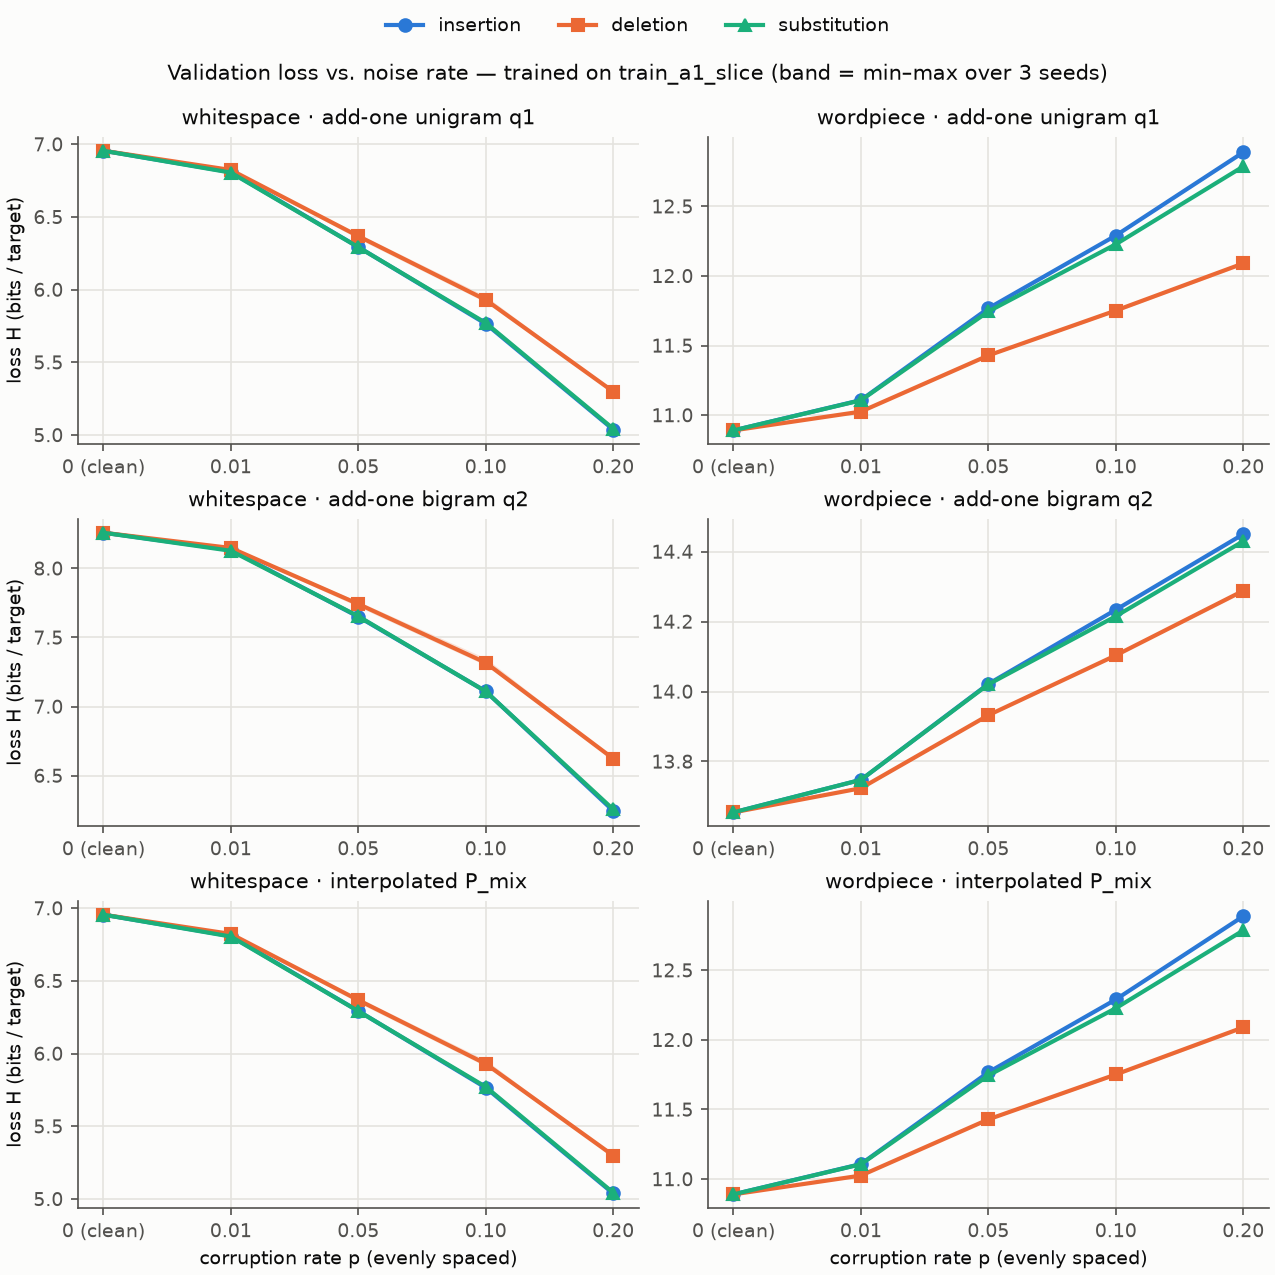

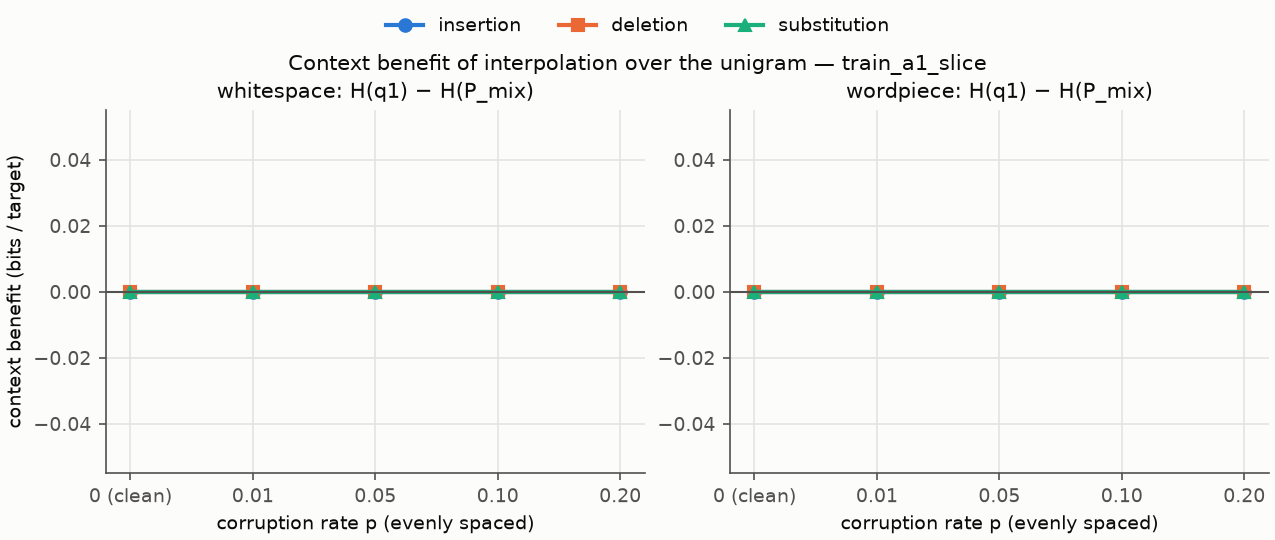

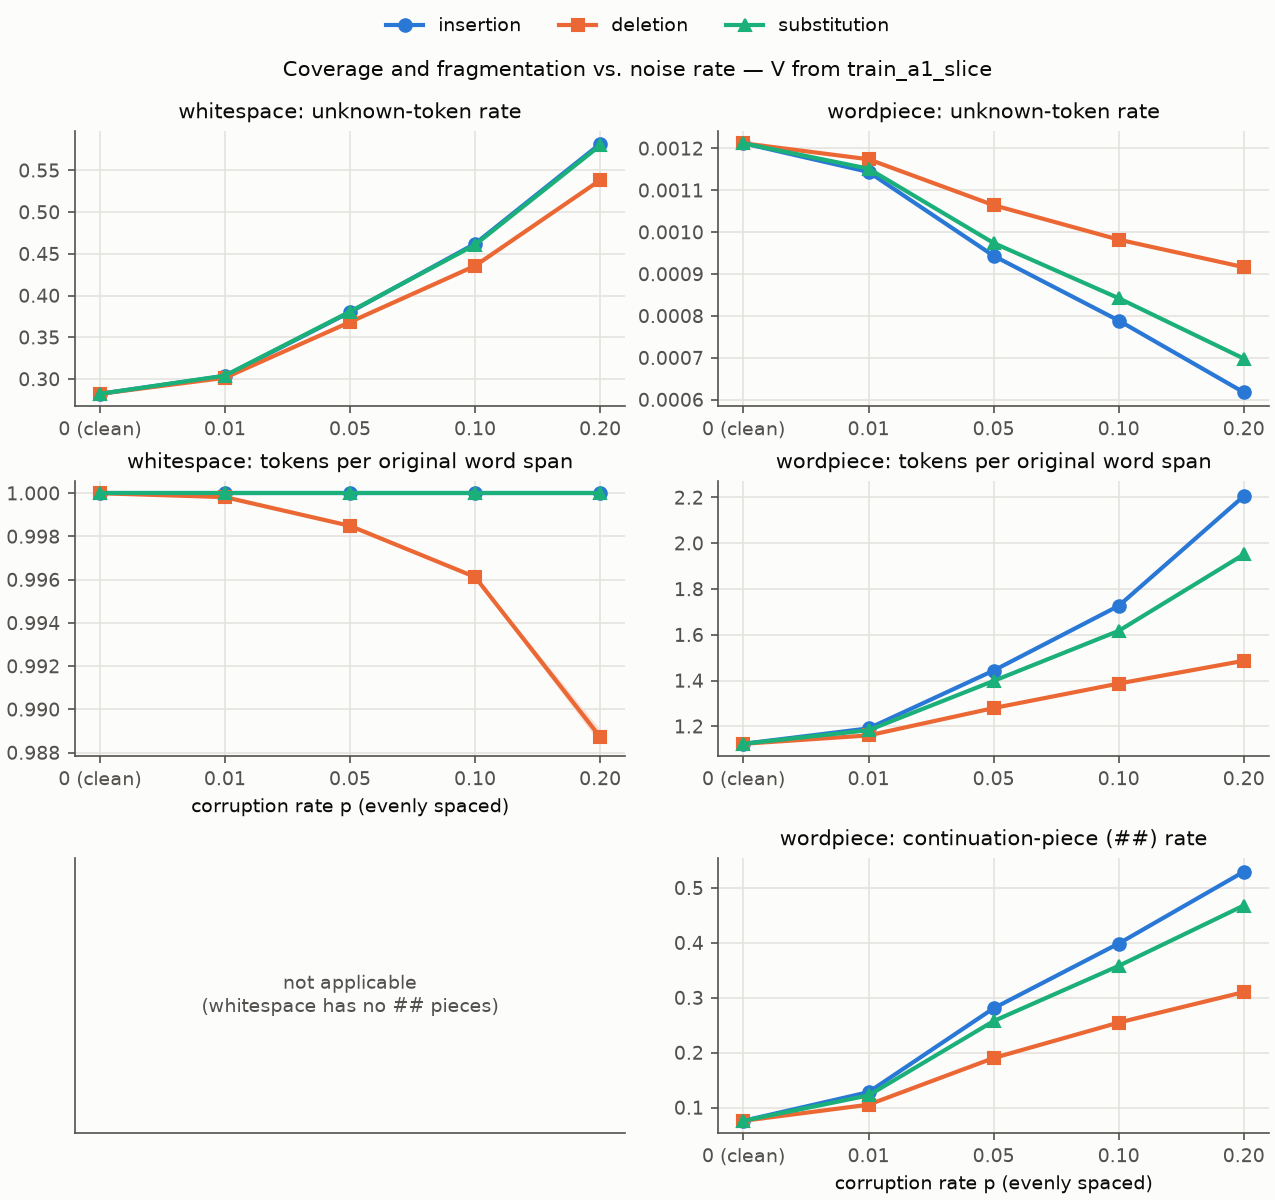

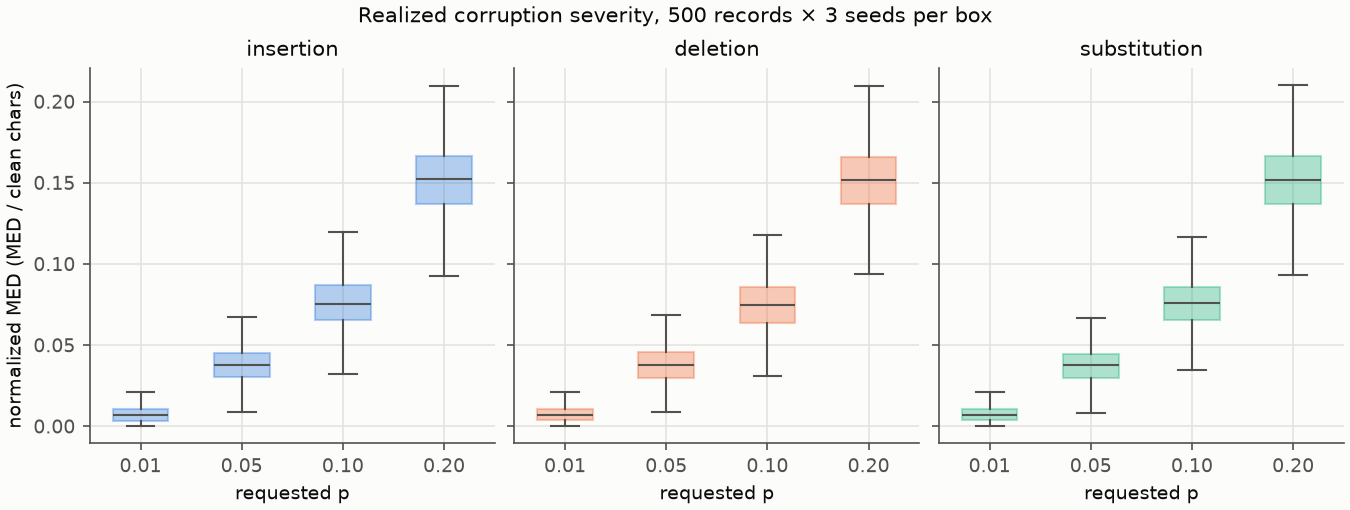

In [19]:
def load_csv(train_set, name):
    return pd.read_csv(RESULTS_P2_DIR / train_set / f"{name}.csv")

figs = [
    figures.loss_vs_rate(load_csv("train_a1_slice", "summary"), "train_a1_slice", FIG_DIR / "loss_vs_rate_train_a1_slice.png"),
    figures.context_benefit_fig(load_csv("train_a1_slice", "context_benefit"), "train_a1_slice", FIG_DIR / "context_benefit_train_a1_slice.png"),
    figures.coverage_fig(load_csv("train_a1_slice", "coverage"), "train_a1_slice", FIG_DIR / "coverage_train_a1_slice.png"),
    figures.severity_fig(pd.read_csv(RESULTS_P2_DIR / "severity_records.csv"), FIG_DIR / "severity.png"),
]
for f in figs:
    display(Image(filename=str(f)))

## 15. Error analysis — three traceable examples  *(both)*

Selected deterministically from the saved per-record rows (A1-slice engines, `P_mix`, seed 11,
p = 0.20). Each example names its record ID, article ID and condition, so it traces back to the
manifests. Example 1 is chosen to **challenge a simple robustness story**.

In [20]:
pr = per_record[per_record.model == "p_mix"].copy()
pr["loss_per_target"] = pr.nll_bits_sum / pr["T"]
clean_pr = pr[pr.condition_id == "clean"].set_index(["tokenizer", "record_id"])
def delta(df):
    c = clean_pr.loc[list(zip(df.tokenizer, df.record_id))]
    df = df.copy()
    df["clean_loss_per_target"] = c["loss_per_target"].values
    df["clean_T"] = c["T"].values
    df["clean_n_unk"] = c["n_unk"].values
    df["delta_loss_per_target"] = df.loss_per_target - df.clean_loss_per_target
    return df

rows_by_id = {cid: {r["record_id"]: r for r in rows} for cid, rows in condition_rows.items()}
examples = []

# 1 — challenges robustness: whitespace loss FALLS under heavy substitution
d1 = delta(pr[(pr.tokenizer == "whitespace") & (pr.condition_id == "sub-p0.20-s11")])
e1 = d1.sort_values(["delta_loss_per_target", "record_id"]).iloc[0]
eng_ws = engines["whitespace"]
q_unk = eng_ws.lm.q(1, (), eng_ws.vocab.unk_id)
examples.append(("1. Whitespace loss falls under 20% substitution (challenges 'noise always hurts')", e1,
    f"<UNK> tokens rose from {e1.clean_n_unk} to {e1.n_unk} of {int(e1.n_tokens)}. Under the slice vocabulary "
    f"(|V| = {eng_ws.vocab.size}) <UNK> is the most frequent target: q1(<UNK>) = {q_unk:.3f} "
    f"({-math.log2(q_unk):.2f} bits), far cheaper than a typical in-vocabulary word. Corrupted words collapse into "
    f"that cheap symbol, so the per-target loss drops by {-e1.delta_loss_per_target:.2f} bits. The lower score "
    f"reflects unknown-token collapse, not robustness."))

# 2 — WordPiece: largest per-target loss increase under substitution
d2 = delta(pr[(pr.tokenizer == "wordpiece") & (pr.condition_id == "sub-p0.20-s11")])
e2 = d2.sort_values(["delta_loss_per_target", "record_id"], ascending=[False, True]).iloc[0]
examples.append(("2. WordPiece: largest per-target loss increase under 20% substitution", e2,
    f"The {e2.clean_T}-target clean record became {e2['T']} targets (pieces per original word "
    f"{e2.pieces_per_span:.2f}, continuation rate {e2.continuation_rate:.2f}). Noise changes the prediction "
    f"targets themselves: rare '##' fragments replace frequent whole-word pieces, and the loss rises by "
    f"{e2.delta_loss_per_target:.2f} bits per target."))

# 3 — WordPiece: deletion shortens the text but adds targets
d3 = delta(pr[(pr.tokenizer == "wordpiece") & (pr.condition_id == "del-p0.20-s11")])
d3["target_change"] = d3["T"] - d3.clean_T
e3 = d3.sort_values(["target_change", "record_id"], ascending=[False, True]).iloc[0]
examples.append(("3. WordPiece: deletion removes characters yet adds prediction targets", e3,
    f"Deleting {rows_by_id['del-p0.20-s11'][e3.record_id]['realized_edits']} letters (MED {e3.med}) made the text "
    f"shorter, but the target count grew from {e3.clean_T} to {e3['T']} because damaged words fragment into "
    f"more pieces. Total NLL and T both change, so a per-target loss compares different prediction problems."))

wp_pipe = pipelines["wordpiece"]
md_out = ["# Phase 2 error analysis — train_a1_slice, P_mix", ""]
for title, e, why in examples:
    clean_text = rows_by_id["clean"][e.record_id]["noisy_text"]
    noisy_text = rows_by_id[e.condition_id][e.record_id]["noisy_text"]
    tok = e.tokenizer
    ct = pipelines[tok].tokenize(clean_text)[:18]; nt = pipelines[tok].tokenize(noisy_text)[:18]
    block = [f"## {title}", "",
             f"- record `{e.record_id}` · article `{e.article_id}` · condition `{e.condition_id}` · tokenizer `{tok}`",
             f"- MED {e.med}, normalized MED {e.normalized_med:.3f}",
             f"- loss per target {e.clean_loss_per_target:.3f} → {e.loss_per_target:.3f} bits (Δ {e.delta_loss_per_target:+.3f}); T {e.clean_T} → {e['T']}",
             f"- clean: {clean_text[:170]}…", f"- noisy: {noisy_text[:170]}…",
             f"- clean tokens: `{' '.join(ct)}` …", f"- noisy tokens: `{' '.join(nt)}` …",
             f"- **reading:** {why}", ""]
    md_out += block
    display(Markdown("\n".join(block)))
(RESULTS_P2_DIR / "train_a1_slice" / "examples.md").write_text("\n".join(md_out))

## 1. Whitespace loss falls under 20% substitution (challenges 'noise always hurts')

- record `wt2-valid-000924` · article `wt2-valid-doc-000873` · condition `sub-p0.20-s11` · tokenizer `whitespace`
- MED 10, normalized MED 0.238
- loss per target 8.983 → 4.114 bits (Δ -4.869); T 7 → 7
- clean: CBSSports.com Second Team All @-@ American…
- noisy: CdSSeorts.com decznd Teax dll @-@ zmeqibvn…
- clean tokens: `CBSSports.com Second Team All @-@ American` …
- noisy tokens: `CdSSeorts.com decznd Teax dll @-@ zmeqibvn` …
- **reading:** <UNK> tokens rose from 1 to 5 of 6. Under the slice vocabulary (|V| = 2918) <UNK> is the most frequent target: q1(<UNK>) = 0.112 (3.16 bits), far cheaper than a typical in-vocabulary word. Corrupted words collapse into that cheap symbol, so the per-target loss drops by 4.87 bits. The lower score reflects unknown-token collapse, not robustness.


## 2. WordPiece: largest per-target loss increase under 20% substitution

- record `wt2-valid-000905` · article `wt2-valid-doc-000873` · condition `sub-p0.20-s11` · tokenizer `wordpiece`
- MED 11, normalized MED 0.262
- loss per target 9.782 → 12.964 bits (Δ +3.183); T 8 → 20
- clean: The team posted the following statistics :…
- noisy: The team prssxd tht fgllowick bqttzstics :…
- clean tokens: `the team posted the following statistics :` …
- noisy tokens: `the team pr ##ss ##x ##d th ##t f ##gl ##low ##ick b ##q ##tt ##z ##stic ##s` …
- **reading:** The 8-target clean record became 20 targets (pieces per original word 2.71, continuation rate 0.63). Noise changes the prediction targets themselves: rare '##' fragments replace frequent whole-word pieces, and the loss rises by 3.18 bits per target.


## 3. WordPiece: deletion removes characters yet adds prediction targets

- record `wt2-valid-001855` · article `wt2-valid-doc-001826` · condition `del-p0.20-s11` · tokenizer `wordpiece`
- MED 97, normalized MED 0.164
- loss per target 11.566 → 12.765 bits (Δ +1.199); T 103 → 160
- clean: During the 1906 legislative session , Beckham urged investigation and prosecution of corrupt insurance companies , following the lead of New York attorney Charles Evans H…
- noisy: During he 1906 lislaive session , Beckh urgd investigati ad proecuion of corpt nsrance omanie , fllowing te lead  Ne Yrk ttoey Carles Evns Huhes . I artcular , h recmmend…
- clean tokens: `during the 1906 legislative session , beck ##ham urged investigation and prosecution of corrupt insurance companies , following` …
- noisy tokens: `during he 1906 li ##sl ##ai ##ve session , beck ##h ur ##g ##d invest ##iga ##ti ad` …
- **reading:** Deleting 97 letters (MED 97) made the text shorter, but the target count grew from 103 to 160 because damaged words fragment into more pieces. Total NLL and T both change, so a per-target loss compares different prediction problems.


2884

## 16. Corpus-size extension — `train_full`  *(both)*

Same validation sample, same 37 noisy datasets (read from disk, not regenerated), same rule and
tie-break. Only the training text changes; λ are re-selected on clean validation for this training
set and frozen before noisy scoring. Comparisons are made **within a tokenizer only**. Caveat: the
whitespace |V| changes with the training set, so even within the whitespace pipeline raw perplexity
is not strictly comparable; WordPiece V is fixed and gives the cleaner comparison. Two training
sizes are two points, not a scaling law (cf. Kaplan et al., 2020).

In [21]:
engines_full = build_engines("train_full")
vocab_full = pd.DataFrame([{"tokenizer": tok, "|V|": e.vocab.size, **e.vocab_stats, **e.counts.stats()}
                           for tok, e in engines_full.items()])
(RESULTS_P2_DIR / "train_full").mkdir(exist_ok=True)
vocab_full.to_csv(RESULTS_P2_DIR / "train_full" / "vocab.csv", index=False)
show_table(vocab_full, cols=["tokenizer", "|V|", "training_tokens", "training_tokens_mapped_to_unk", "targets",
                             "distinct_bigrams", "distinct_trigrams"], title="Frozen V and counts — train_full",
           floatfmt="{:.0f}")

cfg, lam_table_full = select_and_freeze(engines_full, condition_rows["clean"], cfg, "train_full")
pd.DataFrame(lam_table_full).to_csv(RESULTS_P2_DIR / "train_full" / "lambda_selection.csv", index=False)
LAMBDAS_FULL = {tok: frozen_lambdas(cfg, "train_full", tok) for tok in engines_full}
print("frozen λ (train_full):", LAMBDAS_FULL)

per_record_full, T_full = run_training_set("train_full", engines_full, LAMBDAS_FULL)
assert len(T_full["scores"]) == 222 and len(T_full["summary"]) == 78

**Frozen V and counts — train_full**

| tokenizer | |V| | training_tokens | training_tokens_mapped_to_unk | targets | distinct_bigrams | distinct_trigrams |
|---|---|---|---|---|---|---|
| whitespace | 44205 | 2007146 | 31939 | 2024702 | 647349 | 1417409 |
| wordpiece | 29525 | 2256525 | 429 | 2274081 | 656460 | 1499707 |

frozen λ (train_full): {'whitespace': (0.75, 0.25, 0.0), 'wordpiece': (0.5, 0.5, 0.0)}


train_full: 111,000 per-record rows, 222 scores, 78 summary rows in 4.8s


**Corpus size: A1 slice (31k words) vs full train (2.0M words) — within tokenizer only**

| tokenizer | model | |V|_slice | |V|_full | clean_unk_rate_slice | clean_unk_rate_full | clean_H_slice | clean_H_full | ΔH_sub_p0.20_slice | ΔH_sub_p0.20_full | ΔH_del_p0.20_slice | ΔH_del_p0.20_full |
|---|---|---|---|---|---|---|---|---|---|---|---|
| whitespace | q1 | 2918.0000 | 44205.0000 | 0.2823 | 0.0522 | 6.9551 | 10.0583 | -1.9119 | -2.5136 | -1.6565 | -1.6738 |
| whitespace | q2 | 2918.0000 | 44205.0000 | 0.2823 | 0.0522 | 8.2581 | 11.4555 | -2.0026 | -2.7324 | -1.6353 | -1.4423 |
| whitespace | p_mix | 2918.0000 | 44205.0000 | 0.2823 | 0.0522 | 6.9551 | 9.8627 | -1.9119 | -2.3809 | -1.6565 | -1.5320 |
| wordpiece | q1 | 29525.0000 | 29525.0000 | 0.0012 | 0.0012 | 10.8902 | 10.4024 | 1.8958 | 1.9646 | 1.1995 | 1.1820 |
| wordpiece | q2 | 29525.0000 | 29525.0000 | 0.0012 | 0.0012 | 13.6545 | 11.2502 | 0.7752 | 2.2770 | 0.6336 | 1.8860 |
| wordpiece | p_mix | 29525.0000 | 29525.0000 | 0.0012 | 0.0012 | 10.8902 | 10.0676 | 1.8958 | 2.2372 | 1.1995 | 1.5442 |

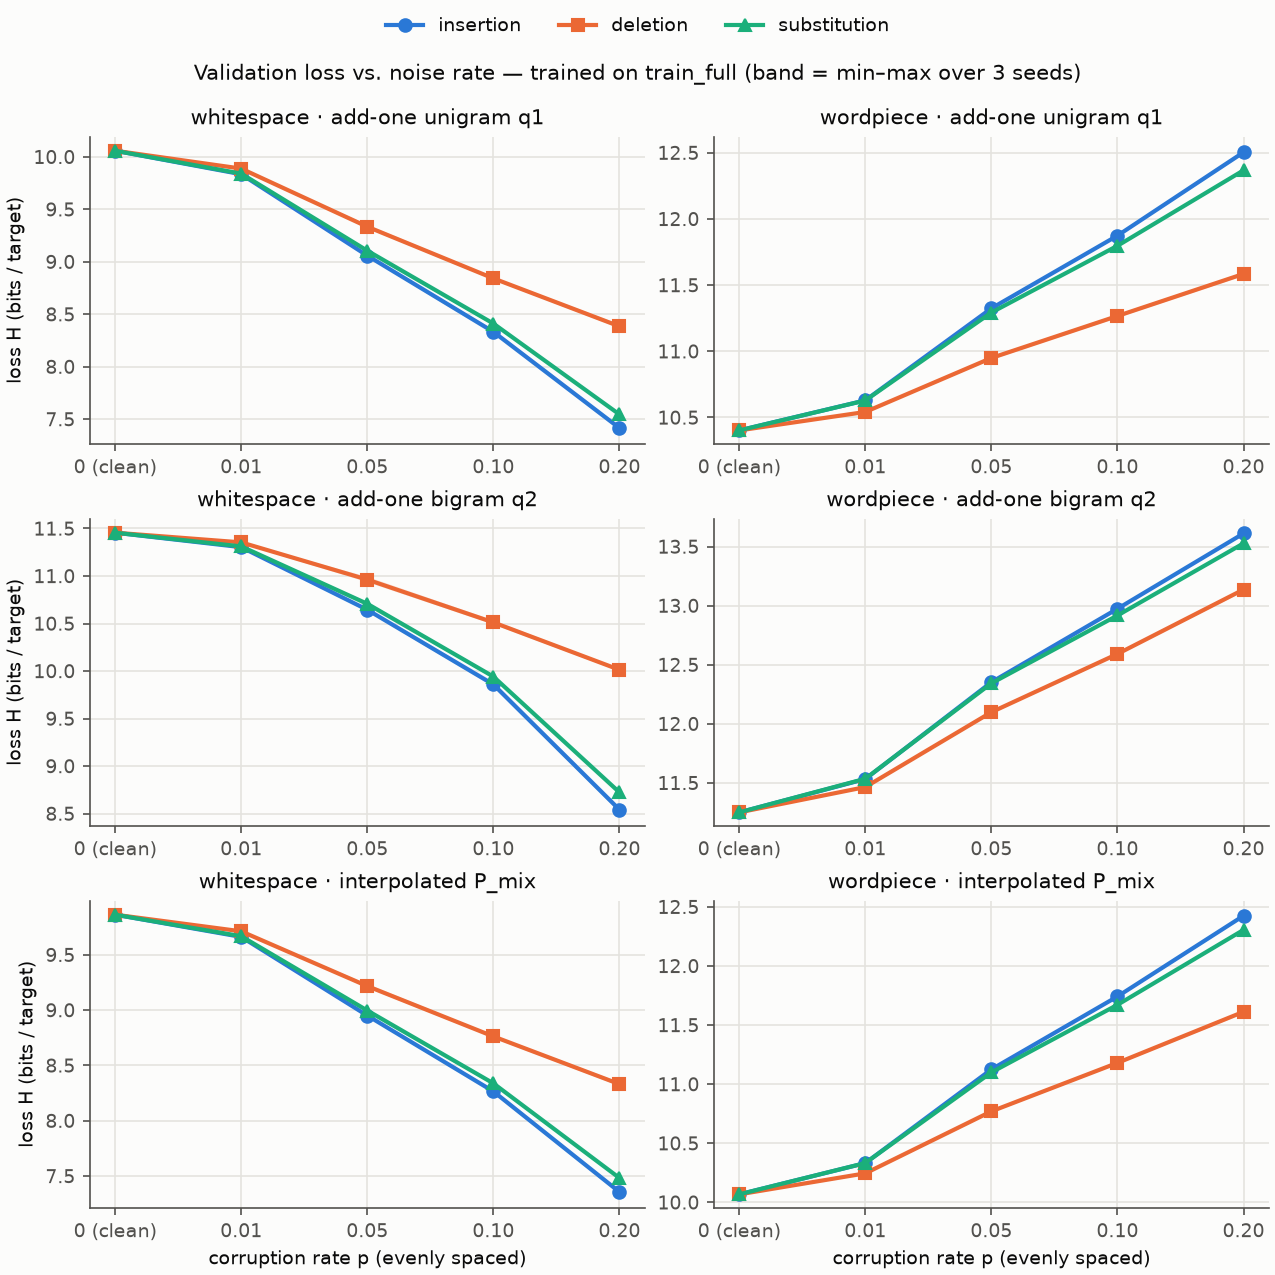

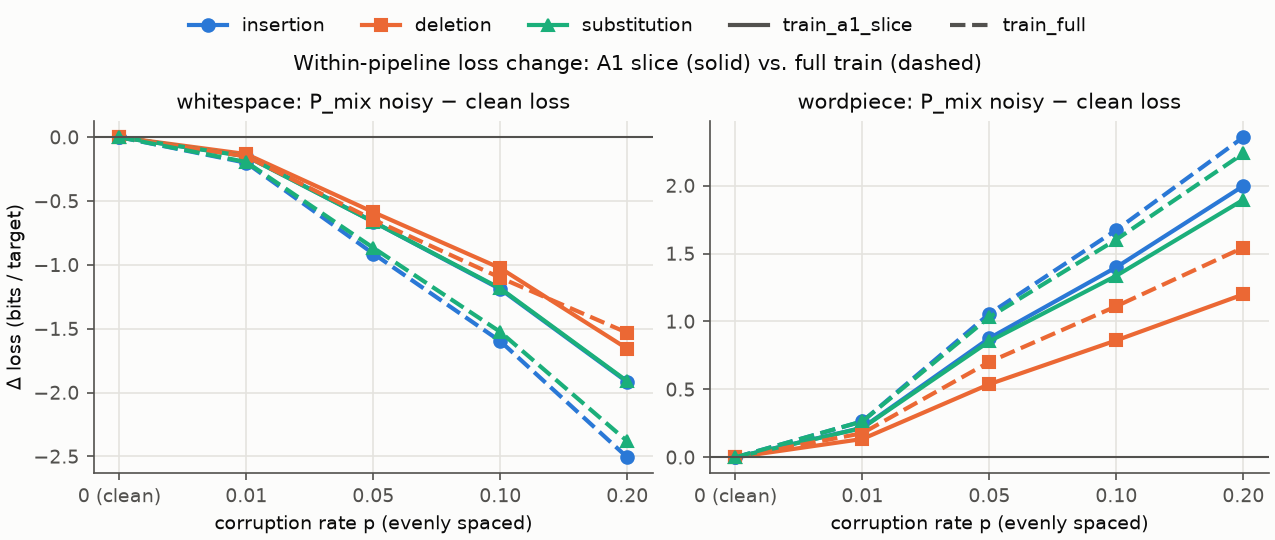

In [22]:
rows = []
for tok in ["whitespace", "wordpiece"]:
    for model in MODELS:
        r = {"tokenizer": tok, "model": model}
        for ts, T in [("slice", T_slice), ("full", T_full)]:
            s = T["summary"]; s = s[(s.tokenizer == tok) & (s.model == model)]
            r[f"clean_H_{ts}"] = float(s[s.operation == "none"].H_bits_mean.iloc[0])
            for op in cfg.operations:
                r[f"ΔH_{op[:3]}_p0.20_{ts}"] = float(s[(s.operation == op) & (s.p == 0.2)].delta_H_bits_mean.iloc[0])
        rows.append(r)
size_cmp = pd.DataFrame(rows)
for ts, e, T in [("slice", engines, T_slice), ("full", engines_full, T_full)]:
    cv = T["coverage"]
    for tok in ["whitespace", "wordpiece"]:
        size_cmp.loc[size_cmp.tokenizer == tok, f"|V|_{ts}"] = e[tok].vocab.size
        size_cmp.loc[size_cmp.tokenizer == tok, f"clean_unk_rate_{ts}"] = float(
            cv[(cv.tokenizer == tok) & (cv.condition_id == "clean")].unk_rate.iloc[0])
size_cmp.to_csv(RESULTS_P2_DIR / "corpus_size_comparison.csv", index=False)
show_table(size_cmp, cols=["tokenizer", "model", "|V|_slice", "|V|_full", "clean_unk_rate_slice", "clean_unk_rate_full",
                           "clean_H_slice", "clean_H_full", "ΔH_sub_p0.20_slice", "ΔH_sub_p0.20_full",
                           "ΔH_del_p0.20_slice", "ΔH_del_p0.20_full"],
           title="Corpus size: A1 slice (31k words) vs full train (2.0M words) — within tokenizer only")

both = pd.concat([load_csv("train_a1_slice", "summary"), load_csv("train_full", "summary")])
figs2 = [figures.loss_vs_rate(load_csv("train_full", "summary"), "train_full", FIG_DIR / "loss_vs_rate_train_full.png"),
         figures.context_benefit_fig(load_csv("train_full", "context_benefit"), "train_full", FIG_DIR / "context_benefit_train_full.png"),
         figures.coverage_fig(load_csv("train_full", "coverage"), "train_full", FIG_DIR / "coverage_train_full.png"),
         figures.corpus_size_fig(both, FIG_DIR / "corpus_size.png")]
for f in figs2[::3]:
    display(Image(filename=str(f)))

## 17. A7 — the 20 Assignment 1 diagnostic pairs (regression)  *(both)*

Regenerated with the **A1 rule** and Phase 1 configuration, then compared byte-for-byte with
`evidence/pairs/pairs.jsonl`. They are a regression check, not the aggregate evaluation sample.

In [23]:
from src.tokenizer.wrapper import TokenizerWrapper
from src.integration.generate_pairs import pair_schedule, build_pair_record
from src.integration.schema import write_jsonl

slice_examples = load_slice()
plan = pair_schedule(cfg1.pairs_count, cfg1.noise_operations, cfg1.noise_intensity)
wrapper = TokenizerWrapper(cfg1)
rerun = [build_pair_record(ex, op, it, wrapper, cfg1)[0] for ex, (op, it) in zip(slice_examples, plan)]
rerun_path = write_jsonl(rerun, EVIDENCE_P2_DIR / "a1_pairs_rerun.jsonl")
pairs_identical = rerun_path.read_bytes() == (PAIRS_DIR / "pairs.jsonl").read_bytes()
msg = f"20 A1 pairs regenerated: {len(rerun)} records; byte-identical to evidence/pairs/pairs.jsonl: {pairs_identical}"
(EVIDENCE_P2_DIR / "a1_pairs_regression.txt").write_text(msg + "\n")
print(msg)
assert pairs_identical

20 A1 pairs regenerated: 20 records; byte-identical to evidence/pairs/pairs.jsonl: True


## 18. Tests + acceptance checklist  *(both)*

The full unit-test suite (Phase 1 + Phase 2) is run and saved, then every box of the plan's
acceptance checklist (§9) is checked in code. Output: `evidence/phase2/acceptance.txt`.

In [24]:
proc = subprocess.run([sys.executable, "-m", "pytest", "-q", "--color=no"], capture_output=True, text=True, cwd=ROOT)
(EVIDENCE_P2_DIR / "pytest.txt").write_text(proc.stdout + proc.stderr)
print(proc.stdout[-1500:])
tests_pass = proc.returncode == 0
a1_proc = subprocess.run([sys.executable, "-m", "pytest", "-q", "--color=no", "tests/test_med.py", "tests/test_noise.py"],
                         capture_output=True, text=True, cwd=ROOT)
a1_tests_pass = a1_proc.returncode == 0

........................................................                 [100%]
56 passed in 1.63s



In [25]:
checks = []
def check(name, ok):
    checks.append({"check": name, "result": "PASS" if ok else "FAIL"}); return ok

all_rows = [r for rows in condition_rows.values() for r in rows]
clean_ok = all(r["noisy_text"] == v["text"] for r, v in zip(condition_rows["clean"], val))
check("All Assignment 1 MED and reproducibility tests still pass; p = 0 leaves the input unchanged",
      a1_tests_pass and clean_ok and z[0] == demo["text"])

v2_ok = True
val_text = {v["record_id"]: v["text"] for v in val}
for r in all_rows:
    clean_t = val_text[r["record_id"]]
    log = r["operation_log"]
    v2_ok &= replay_v2(clean_t, log) == r["noisy_text"]
    v2_ok &= all(clean_t[e["index"]].isascii() and clean_t[e["index"]].isalpha() for e in log)
    v2_ok &= all(clean_t.count(sp) == r["noisy_text"].count(sp) for sp in cfg.protected_spans)
    v2_ok &= r["realized_edits"] <= r["eligible_count"]
    if r["operation"] == "insertion":
        v2_ok &= len(r["noisy_text"]) == len(clean_t) + r["realized_edits"]
check("Noise v2: letters only, insert-after, no re-corruption, sentinels preserved, replay exact (all 18,500 rows)", v2_ok)

check("Every smoothed distribution sums to 1 for observed and unseen histories; all allowed targets > 0", normalization_ok)
check("Hand vocab {a, b, end} gives 3/6, 2/6, 1/6", all(r["match"] for r in hand[:3]))

lam_ok = all(min(l) >= 0 and abs(sum(l) - 1) < 1e-12 for L in (LAMBDAS, LAMBDAS_FULL) for l in L.values())
lam_frozen = (load_phase2_config().frozen_lambdas.get("train_a1_slice") == {k: list(v) for k, v in LAMBDAS.items()}
              and load_phase2_config().frozen_lambdas.get("train_full") == {k: list(v) for k, v in LAMBDAS_FULL.items()})
check("λ nonnegative, sum to 1, selected on clean val, frozen in configs/phase2.yaml before the noisy grid; P_mix normalized",
      lam_ok and lam_frozen and hand[-1]["match"])
check("Four equally likely targets give 2 bits / PP 4; corpus aggregation matches the hand calculation",
      all(r["match"] for r in hand[3:9]))
check("Unseen whitespace tokens map to <UNK>; boundaries reset context; evaluation never mutates counts or V",
      unk_ok and counts_unchanged and tests_pass)
check("Unsmoothed MLE demo shows infinite loss on a zero-probability event", mle_inf)
check("p = 0 gives the identical clean score for every seed", clean_invariant)
check("222 scores, 6 clean + 72 noisy summary rows saved per training set",
      all(len(pd.read_csv(RESULTS_P2_DIR / ts / "scores.csv")) == 222
          and len(pd.read_csv(RESULTS_P2_DIR / ts / "summary.csv")) == 78 for ts in ("train_a1_slice", "train_full")))
same_inputs = all(set(map(tuple, g[["condition_id", "record_id"]].drop_duplicates().values.tolist()))
                  == set((c, r["record_id"]) for c, rows in condition_rows.items() for r in rows)
                  for _, g in per_record.groupby("tokenizer"))
hashes_ok = all(r["protocol_sha256"] == cfg.protocol_sha256 and len(r["source_text_sha256"]) == 64 for r in all_rows)
check("Every noisy text generated once and shared by both tokenizers; manifests carry source and config hashes",
      same_inputs and hashes_ok)
check("Empty-after-noise records kept, </s> scored, undefined rates flagged",
      (per_record["T"] >= 1).all() and (per_record[per_record.n_tokens == 0].rate_undefined).all()
      and len(per_record) == 37 * 500 * 2 * 3)
check("20 A1 diagnostic pairs reproduce byte-identically", pairs_identical)
no_test = (not per_record.record_id.str.startswith("wt2-test").any()
           and not any(r["record_id"].startswith("wt2-test") for recs in train_sets.values() for r in recs))
check("Test split never scored, inspected, or used for any choice", no_test)
readme = (ROOT / "README.md").read_text()
summary_doc = ROOT / "docs" / "phase2_summary.md"
check("§17: README reproduces a headline table; plotted points trace to saved CSVs; write-up states metric limits; outputs reusable",
      "phase2.ipynb" in readme and "summary.csv" in readme
      and all((FIG_DIR / n).exists() for n in ["loss_vs_rate_train_a1_slice.png", "severity.png", "corpus_size.png"])
      and summary_doc.exists() and "cannot" in summary_doc.read_text())
check("Full unit-test suite passes", tests_pass)

show_table(checks, title="Phase 2 acceptance checklist (plan §9)")
report = "\n".join(f"[{c['result']}] {c['check']}" for c in checks)
(EVIDENCE_P2_DIR / "acceptance.txt").write_text(report + "\n")
assert all(c["result"] == "PASS" for c in checks), "an acceptance check failed"
print("ALL PHASE 2 ACCEPTANCE CHECKS PASS")

**Phase 2 acceptance checklist (plan §9)**

| check | result |
|---|---|
| All Assignment 1 MED and reproducibility tests still pass; p = 0 leaves the input uncha... | PASS |
| Noise v2: letters only, insert-after, no re-corruption, sentinels preserved, replay exa... | PASS |
| Every smoothed distribution sums to 1 for observed and unseen histories; all allowed ta... | PASS |
| Hand vocab {a, b, end} gives 3/6, 2/6, 1/6 | PASS |
| λ nonnegative, sum to 1, selected on clean val, frozen in configs/phase2.yaml before th... | PASS |
| Four equally likely targets give 2 bits / PP 4; corpus aggregation matches the hand cal... | PASS |
| Unseen whitespace tokens map to <UNK>; boundaries reset context; evaluation never mutat... | PASS |
| Unsmoothed MLE demo shows infinite loss on a zero-probability event | PASS |
| p = 0 gives the identical clean score for every seed | PASS |
| 222 scores, 6 clean + 72 noisy summary rows saved per training set | PASS |
| Every noisy text generated once and shared by both tokenizers; manifests carry source a... | PASS |
| Empty-after-noise records kept, </s> scored, undefined rates flagged | PASS |
| 20 A1 diagnostic pairs reproduce byte-identically | PASS |
| Test split never scored, inspected, or used for any choice | PASS |
| §17: README reproduces a headline table; plotted points trace to saved CSVs; write-up s... | PASS |
| Full unit-test suite passes | PASS |

ALL PHASE 2 ACCEPTANCE CHECKS PASS


In [26]:
run_info = {
    "protocol_sha256": cfg.protocol_sha256,
    "config_file_sha256": sha256_file(PHASE2_CONFIG_PATH),
    "frozen_lambdas": cfg.frozen_lambdas,
    "val_sample_sha256": sha256_file(VAL_PATH),
    "training_set_sha256": {k: sha256_file(p) for k, p in TRAIN_PATHS.items()},
    "grid_index_sha256": sha256_file(RESULTS_P2_DIR / "grid_index.csv"),
    "env": {"python": platform.python_version(), "transformers": transformers.__version__,
            "tokenizers": tokenizers.__version__, "numpy": np.__version__, "pandas": pd.__version__},
    "runtime_seconds": round(time.time() - T0, 1),
}
(RESULTS_P2_DIR / "run_info.json").write_text(json.dumps(run_info, indent=2))
print(json.dumps(run_info, indent=2))

{
  "protocol_sha256": "9eb487cc5deea14c60931cfec70b1bf4bacaf13d23be2cd8634dd7aae3bc10a6",
  "config_file_sha256": "f79c4591784dc0c512fc34ef31f61a7ad15d3f6f0c823dceba2148475d64fcac",
  "frozen_lambdas": {
    "train_a1_slice": {
      "whitespace": [
        1.0,
        0.0,
        0.0
      ],
      "wordpiece": [
        1.0,
        0.0,
        0.0
      ]
    },
    "train_full": {
      "whitespace": [
        0.75,
        0.25,
        0.0
      ],
      "wordpiece": [
        0.5,
        0.5,
        0.0
      ]
    }
  },
  "val_sample_sha256": "4894ff5d0baf2805ef6c0c5ee85579a0139ffb789c77c01fdecdb056c4548a7b",
  "training_set_sha256": {
    "train_a1_slice": "967fd344fb0ad152cb7bea73b5031cef951165a2df5d9f404a349887f5ab289c",
    "train_full": "45b9784cac97f332aa9bd41010689fab431fe03131cf949715c3eecb83a60378"
  },
  "grid_index_sha256": "74ae5262edb08ad586c87b3acd23b432099f681c1976b444525408cb360bb74b",
  "env": {
    "python": "3.13.11",
    "transformers": "5.16.1",
    

## 19. Artifacts produced

| Path | What |
|---|---|
| `configs/phase2.yaml` | frozen protocol + λ written by step B6 |
| `derived/phase2/val_sample.jsonl` (+ `.sha256`) | 500 validation records with article IDs |
| `derived/phase2/train_a1_slice.jsonl`, `train_full.jsonl` (+ `.sha256`) | the two clean training sets |
| `derived/phase2/noisy/<condition_id>.jsonl` | 37 datasets: noisy text + full corruption manifest per record |
| `results/phase2/grid_index.csv`, `severity.csv`, `severity_records.csv` | grid file hashes; requested p vs realized normalized MED |
| `results/phase2/<train_set>/per_record.parquet` | one row per record × condition × tokenizer × model |
| `results/phase2/<train_set>/scores.csv` | the 222 individual scores |
| `results/phase2/<train_set>/summary.csv` | 6 clean + 72 noisy rows (mean/min/max over seeds) |
| `results/phase2/<train_set>/within_pipeline.csv`, `context_benefit.csv`, `coverage.csv` | required §9 measures |
| `results/phase2/<train_set>/vocab.csv`, `lambda_selection.csv`, `examples.md` | V and counts, λ search, error analysis |
| `results/phase2/corpus_size_comparison.csv`, `figures/*.png`, `run_info.json` | extension table, figures, hashes |
| `evidence/phase2/*` | pytest output, acceptance checklist, hand check, MLE demo, fast-MED check, 20-pair regression |
| `docs/phase2_summary.md` | Phase 2 write-up (interpretation, limitations, ethics) |